# CC3092 - Deep Learning y Sistemas Inteligentes
## Laboratorio #6: Transfer Learning y Fine-Tuning

Comparación de tres estrategias para clasificar **CIFAR-10**: una CNN entrenada desde cero, **VGG-16 como extractor de características** (backbone congelado) y **VGG-16 con fine-tuning** de los bloques convolucionales superiores. Además de las métricas de clasificación se mide el costo computacional de cada estrategia (parámetros, FLOPs, tiempo, memoria de GPU).

In [1]:
import copy
import gc
import json
import math
import os
import platform
import random
import subprocess
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.flop_counter import FlopCounterMode

from torchvision import datasets, transforms
from torchvision.models import vgg16, VGG16_Weights
from torchvision.transforms import v2
from torchinfo import summary

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
plt.rcParams["figure.dpi"] = 100

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)


def set_seed(seed):
    """Fija todas las semillas relevantes para reproducibilidad entre iteraciones."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def sync():
    """Espera a que termine el trabajo pendiente en GPU (los kernels de CUDA son asincronos)."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def peak_mem_mb():
    """Memoria pico asignada por PyTorch en GPU desde el ultimo reset, en MB."""
    return torch.cuda.max_memory_allocated() / 1024**2 if DEVICE.type == "cuda" else 0.0


def get_cpu_name():
    """Nombre comercial de la CPU (Windows via PowerShell, con fallback a platform)."""
    try:
        out = subprocess.check_output(
            ["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name"], text=True
        )
        return out.strip()
    except Exception:
        return platform.processor()


HARDWARE = {
    "GPU": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "N/A",
    "VRAM (GB)": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1) if DEVICE.type == "cuda" else 0,
    "CPU": get_cpu_name(),
    "Nucleos logicos": os.cpu_count(),
    "PyTorch": torch.__version__,
    "CUDA (build)": torch.version.cuda,
}
for k, v in HARDWARE.items():
    print(f"{k}: {v}")

W0927 21:12:15.705000 14688 torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Dispositivo: cuda


GPU: NVIDIA GeForce RTX 3060 Ti
VRAM (GB): 8.0
CPU: AMD Ryzen 5 7600 6-Core Processor
Nucleos logicos: 12
PyTorch: 2.14.0+cu126
CUDA (build): 12.6


## 1. Dataset

Se utiliza el dataset público **CIFAR-10**: 60,000 imágenes a color de 32×32 píxeles en 10 categorías, con un split oficial de 50,000 imágenes de entrenamiento y 10,000 de test. Se carga con `torchvision.datasets.CIFAR10`.

Toda la configuración del experimento vive en el diccionario `CONFIG` (tamaño de validación, batch, resolución de VGG-16, precisión mixta, carpetas de salida). El conjunto de validación (5,000 imágenes) se obtiene del split de entrenamiento de forma estratificada y el split oficial de test se reserva para la evaluación final.

In [2]:
CONFIG = {
    "data_root": "./data",
    "val_size": 5000,               # 45,000 train / 5,000 val
    "random_state": 42,
    "eval_batch_size": 128,
    "vgg_resolution": 128,          # resolucion de entrada de VGG-16 (misma para extractor y fine-tuning)
    "use_amp": True,                # precision mixta fp16 en entrenamiento y validacion
    "low_data_fraction": 0.10,      # fraccion del train para el experimento de la seccion 4.1
    "results_dir": "./results",      # resultados de cada iteracion (json), permiten reanudar el notebook
    "checkpoints_dir": "./checkpoints",
    "figures_dir": "./figuras",
    "reuse_cache": True,            # si existe results/<iteracion>.json con la misma config, no se reentrena
}
for d in ("results_dir", "checkpoints_dir", "figures_dir"):
    Path(CONFIG[d]).mkdir(parents=True, exist_ok=True)

set_seed(CONFIG["random_state"])

train_raw = datasets.CIFAR10(root=CONFIG["data_root"], train=True, download=True)
test_raw = datasets.CIFAR10(root=CONFIG["data_root"], train=False, download=True)

CLASSES = train_raw.classes
print("Train (oficial):", len(train_raw), "| Test (oficial):", len(test_raw))
print("Clases:", CLASSES)

Train (oficial): 50000 | Test (oficial): 10000
Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 2. Exploración y preparación de los datos

Observaciones totales (train + test): 60000
Numero de clases: 10


,clase,train,test,train_pct
0,airplane,5000,1000,10.0
1,automobile,5000,1000,10.0
2,bird,5000,1000,10.0
3,cat,5000,1000,10.0
4,deer,5000,1000,10.0
5,dog,5000,1000,10.0
6,frog,5000,1000,10.0
7,horse,5000,1000,10.0
8,ship,5000,1000,10.0
9,truck,5000,1000,10.0


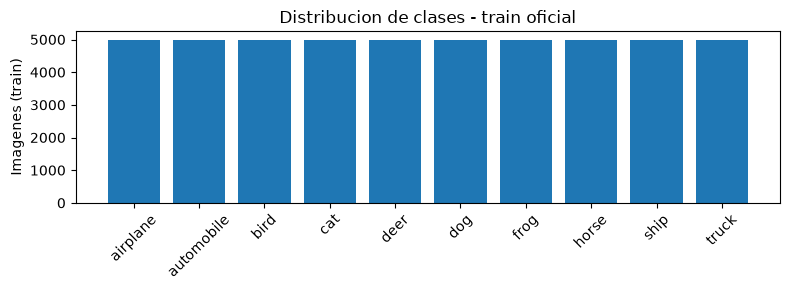

In [3]:
train_targets = np.array(train_raw.targets)
test_targets = np.array(test_raw.targets)

classes_idx, train_counts = np.unique(train_targets, return_counts=True)
_, test_counts = np.unique(test_targets, return_counts=True)

balance_df = pd.DataFrame({"clase": CLASSES, "train": train_counts, "test": test_counts})
balance_df["train_pct"] = (balance_df["train"] / balance_df["train"].sum() * 100).round(2)

print("Observaciones totales (train + test):", len(train_raw) + len(test_raw))
print("Numero de clases:", len(classes_idx))
display(balance_df)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(balance_df["clase"], balance_df["train"])
ax.set_ylabel("Imagenes (train)")
ax.set_title("Distribucion de clases - train oficial")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**¿Cuántas observaciones y cuántas clases tiene el dataset? ¿Las clases están balanceadas?**

CIFAR-10 tiene **60,000 observaciones** (50,000 de entrenamiento y 10,000 de test) y **10 clases**. Las clases están **perfectamente balanceadas**: 5,000 imágenes por clase en train (10.00 % cada una) y 1,000 por clase en test. El split estratificado conserva ese balance: 4,500 imágenes por clase en el train de 45,000 y 500 por clase en validación. Por eso no hace falta re-muestrear ni ponderar la pérdida por clase, y la accuracy es una métrica representativa (se reportan además precision, recall y F1 macro).

In [4]:
sample = train_raw.data[0]
print("Forma de una imagen (H, W, C):", sample.shape)
print("Dtype crudo:", train_raw.data.dtype, "| rango:", train_raw.data.min(), "-", train_raw.data.max())

# Split estratificado 45,000 / 5,000 sobre el train oficial
train_idx, val_idx = train_test_split(
    np.arange(len(train_raw)),
    test_size=CONFIG["val_size"],
    random_state=CONFIG["random_state"],
    stratify=train_targets,
)
print("Train:", len(train_idx), "| Val:", len(val_idx))
print("Balance en val (imagenes por clase):", np.bincount(train_targets[val_idx]))

# Datasets completos como tensores uint8 (N, 3, 32, 32) residentes en GPU: la augmentation y el
# redimensionamiento se hacen por batch en GPU, sin DataLoader ni workers.
def to_gpu_uint8(np_images):
    """Convierte un arreglo (N, 32, 32, 3) uint8 de numpy en un tensor (N, 3, 32, 32) uint8 en el dispositivo."""
    return torch.from_numpy(np_images).permute(0, 3, 1, 2).contiguous().to(DEVICE)


X_all_train = to_gpu_uint8(train_raw.data)
y_all_train = torch.from_numpy(train_targets).to(DEVICE)
X_test = to_gpu_uint8(test_raw.data)
y_test = torch.from_numpy(test_targets).to(DEVICE)

X_train, y_train = X_all_train[train_idx], y_all_train[train_idx]
X_val, y_val = X_all_train[val_idx], y_all_train[val_idx]

# Media y desviacion estandar por canal, calculadas SOLO sobre el train (45,000 imagenes), en escala [0, 1]
channel_mean, channel_std = [], []
for c in range(3):
    ch = X_train[:, c].float() / 255.0
    channel_mean.append(ch.mean().item())
    channel_std.append(ch.std().item())

weights_meta = VGG16_Weights.IMAGENET1K_V1.transforms()
IMAGENET_MEAN, IMAGENET_STD = list(weights_meta.mean), list(weights_meta.std)

stats_df = pd.DataFrame({
    "canal": ["R", "G", "B"],
    "media CIFAR-10": channel_mean,
    "media ImageNet": IMAGENET_MEAN,
    "std CIFAR-10": channel_std,
    "std ImageNet": IMAGENET_STD,
}).round(4)
stats_df["dif. media"] = (stats_df["media CIFAR-10"] - stats_df["media ImageNet"]).round(4)
stats_df["dif. std"] = (stats_df["std CIFAR-10"] - stats_df["std ImageNet"]).round(4)
display(stats_df)

Forma de una imagen (H, W, C): (32, 32, 3)
Dtype crudo: uint8 | rango: 0 - 255
Train: 45000 | Val: 5000
Balance en val (imagenes por clase): [500 500 500 500 500 500 500 500 500 500]


,canal,media CIFAR-10,media ImageNet,std CIFAR-10,std ImageNet,dif. media,dif. std
0,R,0.4911,0.485,0.2469,0.229,0.0061,0.0179
1,G,0.4821,0.456,0.2434,0.224,0.0261,0.0194
2,B,0.4464,0.406,0.2616,0.225,0.0404,0.0366


**¿Cuál es la resolución y el número de canales? ¿Cómo se comparan la media y la desviación estándar con las de ImageNet?**

Cada imagen es de **32×32 píxeles con 3 canales (RGB)**, almacenada como `uint8` en el rango 0-255. Las estadísticas por canal del train (45,000 imágenes, escala [0, 1]) son muy cercanas a las de ImageNet pero no iguales: la media difiere hasta **0.040** (canal azul, 0.446 frente a 0.406) y la desviación estándar hasta **0.037** (canal azul, 0.262 frente a 0.225); CIFAR-10 es en promedio algo más brillante y con más contraste en los tres canales. La diferencia es pequeña, así que usar las estadísticas de ImageNet en VGG-16 no introduce un desajuste importante, y es lo correcto para el backbone preentrenado: sus filtros se entrenaron con entradas normalizadas de esa manera y cambiar la normalización desplazaría sus activaciones. La CNN desde cero usa las estadísticas propias de CIFAR-10, calculadas solo con el conjunto de entrenamiento para evitar fuga de información hacia validación y test.

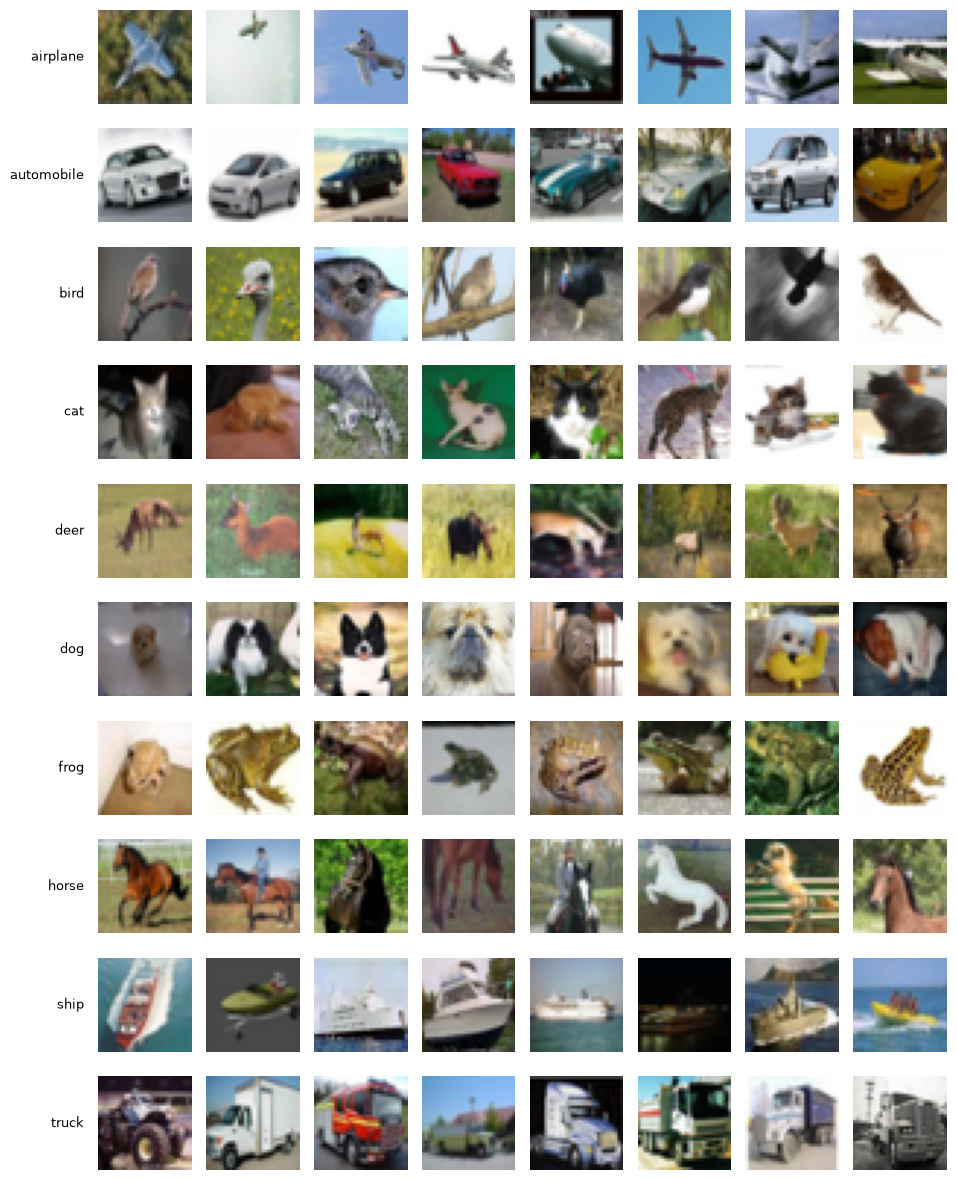

In [5]:
# Al menos 5 ejemplos por clase (se muestran 8 por fila)
n_per_class = 8
rng = np.random.default_rng(CONFIG["random_state"])
fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(n_per_class * 1.2, len(CLASSES) * 1.2))
for row, cls in enumerate(CLASSES):
    idxs = rng.choice(np.where(train_targets == row)[0], size=n_per_class, replace=False)
    for col, i in enumerate(idxs):
        axes[row, col].imshow(train_raw.data[i])
        axes[row, col].axis("off")
    axes[row, 0].text(-0.15, 0.5, cls, transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.subplots_adjust(left=0.1)
plt.savefig(Path(CONFIG["figures_dir"]) / "ejemplos_por_clase.png", bbox_inches="tight")
plt.show()

**¿Qué pares de clases se espera que sean más difíciles de distinguir y por qué?**

Se esperan como más difíciles: (1) **gato-perro**: mamíferos de cuatro patas con pelaje, tamaños y poses parecidos, y a 32×32 los rasgos que los distinguen (forma del hocico y de las orejas) casi desaparecen; (2) **automóvil-camión**: ambos tienen ruedas, ventanas y fondo de carretera y se distinguen sobre todo por proporciones; (3) **venado-caballo**: siluetas parecidas sobre fondos de pasto o campo; (4) **avión-barco** y **pájaro-avión**: objetos alargados sobre fondos azules uniformes (cielo o agua). Además, las clases de animales comparten fondos naturales verdes y marrones. En la Sección 4.6 se contrastan estas hipótesis con las matrices de confusión reales.

### 2.4 Pipelines de preprocesamiento y data augmentation

Los pipelines se implementan **sobre tensores `uint8` en GPU, por batch**, para que el preprocesamiento no sea el cuello de botella (redimensionar 45,000 imágenes por epoch en CPU con PIL costaría más que el propio forward de VGG-16). Son equivalentes a los `transforms` de `torchvision` que se muestran como referencia y se verifica numéricamente la equivalencia del redimensionamiento y la normalización.

- **CNN desde cero (32×32):** *train* = recorte aleatorio con padding de 4 + flip horizontal → escala a [0, 1] → normalización con media/std de CIFAR-10. *val/test* = solo escala y normalización.
- **VGG-16 (128×128):** *train* = mismo recorte + flip a resolución nativa → `Resize` a 128×128 (bilineal) → normalización con media/std de **ImageNet**, que es la que espera el backbone preentrenado. *val/test* = solo `Resize` y normalización.

Pipeline CNN (train):
 Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.49113741517066956, 0.48211121559143066, 0.44644901156425476], std=[0.24686916172504425, 0.24343015253543854, 0.2616034150123596])
) 

Pipeline VGG-16 (train):
 Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Diferencia maxima prep_vgg (GPU) vs torchvision v2: 7.15e-07


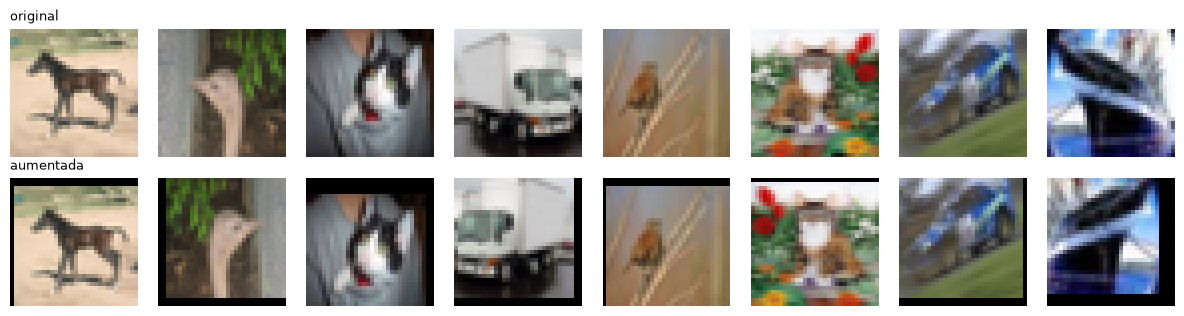

In [6]:
R = CONFIG["vgg_resolution"]
CIFAR_MEAN_T = torch.tensor(channel_mean, device=DEVICE).view(1, 3, 1, 1)
CIFAR_STD_T = torch.tensor(channel_std, device=DEVICE).view(1, 3, 1, 1)
IMNET_MEAN_T = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
IMNET_STD_T = torch.tensor(IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)


def random_crop_flip(x, pad=4):
    """Data augmentation por muestra sobre un batch uint8 (B, 3, 32, 32): recorte aleatorio con padding y flip horizontal."""
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))  # padding con ceros
    oy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ox = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = oy[:, None] + torch.arange(H, device=x.device)[None, :]
    cols = ox[:, None] + torch.arange(W, device=x.device)[None, :]
    flip = torch.rand(B, device=x.device) < 0.5
    cols = torch.where(flip[:, None], cols.flip(1), cols)  # invertir columnas equivale a un flip horizontal
    b_idx = torch.arange(B, device=x.device)[:, None, None, None]
    c_idx = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[b_idx, c_idx, rows[:, None, :, None], cols[:, None, None, :]]


def prep_cnn(x):
    """Pipeline de la CNN desde cero: uint8 -> [0, 1] -> normalizacion con estadisticas de CIFAR-10 (32x32)."""
    return (x.float() / 255.0 - CIFAR_MEAN_T) / CIFAR_STD_T


def prep_vgg(x):
    """Pipeline de VGG-16: uint8 -> [0, 1] -> resize bilineal a RxR -> normalizacion con estadisticas de ImageNet."""
    x = F.interpolate(x.float() / 255.0, size=(R, R), mode="bilinear", align_corners=False)
    return (x - IMNET_MEAN_T) / IMNET_STD_T


PREP = {"cnn": prep_cnn, "vgg": prep_vgg}


def batches(X, y, batch_size, shuffle=False, augment=False, prep=prep_cnn):
    """Itera sobre (X, y) en batches ya preprocesados. La augmentation solo se aplica si augment=True (train)."""
    n = X.shape[0]
    order = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, batch_size):
        b = order[i:i + batch_size]
        xb = X[b]
        if augment:
            xb = random_crop_flip(xb)
        yield prep(xb), y[b]


# Pipelines equivalentes de torchvision (referencia, por imagen)
tv_cnn_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(channel_mean, channel_std)])
tv_vgg_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
    transforms.Resize((R, R)), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
print("Pipeline CNN (train):\n", tv_cnn_train, "\n\nPipeline VGG-16 (train):\n", tv_vgg_train)

# Verificacion: mi resize + normalizacion en GPU vs. torchvision v2 aplicado sobre tensores float
ref = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.Resize((R, R), antialias=True), v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
xs = X_val[:16]
diff_vgg = (prep_vgg(xs) - torch.stack([ref(im) for im in xs])).abs().max().item()
print(f"\nDiferencia maxima prep_vgg (GPU) vs torchvision v2: {diff_vgg:.2e}")

# Verificacion visual de la augmentation: mismas 8 imagenes originales y su version aumentada
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
xa = random_crop_flip(xs[:8])
for j in range(8):
    axes[0, j].imshow(xs[j].permute(1, 2, 0).cpu().numpy()); axes[0, j].axis("off")
    axes[1, j].imshow(xa[j].permute(1, 2, 0).cpu().numpy()); axes[1, j].axis("off")
axes[0, 0].set_title("original", fontsize=9, loc="left"); axes[1, 0].set_title("aumentada", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

#### Costo computacional al cambiar la resolución de entrada

Se cuenta el número de MACs de VGG-16 (solo capas `Conv2d` y `Linear`) para distintas resoluciones de entrada con una función que registra la salida de cada capa mediante *forward hooks*. Esta misma función se reutiliza en la Sección 5 para estimar el costo de entrenamiento.

In [7]:
def layer_macs(model, input_shape):
    """Recorre un forward con hooks y devuelve [(nombre, MACs, entrenable)] de cada Conv2d/Linear en orden de ejecucion.

    MACs conv = Hout*Wout*Cout*(Cin/groups)*kh*kw ; MACs linear = in*out. BatchNorm, ReLU y pooling se ignoran
    (su costo es despreciable frente a conv/linear). 'entrenable' = alguno de sus parametros tiene requires_grad.
    """
    records, hooks = [], []

    def make_hook(name):
        def hook(mod, inp, out):
            if isinstance(mod, nn.Conv2d):
                macs = out.shape[2] * out.shape[3] * mod.out_channels * (mod.in_channels // mod.groups) \
                       * mod.kernel_size[0] * mod.kernel_size[1]
            else:
                macs = mod.in_features * mod.out_features
            records.append((name, macs, any(p.requires_grad for p in mod.parameters())))
        return hook

    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            hooks.append(m.register_forward_hook(make_hook(name)))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        p = next(model.parameters())
        model(torch.zeros(1, *input_shape, device=p.device))
    for h in hooks:
        h.remove()
    model.train(was_training)
    return records


vgg_ref = vgg16(weights=None).to(DEVICE)
rows = []
for res in (32, 64, 112, 128, 224):
    macs = sum(m for _, m, _ in layer_macs(vgg_ref, (3, res, res)))
    rows.append({"resolucion": f"{res}x{res}", "pixeles": res * res, "x pixeles vs 32x32": round(res * res / 1024, 1),
                 "GMACs (VGG-16)": round(macs / 1e9, 2), "GFLOPs (2 x MACs)": round(2 * macs / 1e9, 2)})
res_df = pd.DataFrame(rows)
display(res_df)
del vgg_ref
gc.collect(); torch.cuda.empty_cache()

,resolucion,pixeles,x pixeles vs 32x32,GMACs (VGG-16),GFLOPs (2 x MACs)
0,32x32,1024,1.0,0.44,0.87
1,64x64,4096,4.0,1.38,2.75
2,112x112,12544,12.2,3.96,7.92
3,128x128,16384,16.0,5.13,10.27
4,224x224,50176,49.0,15.47,30.94


**¿Qué transformaciones necesita cada modelo? ¿Qué pasa con el número de píxeles y el cómputo al pasar de 32×32 a 224×224?**

- **CNN desde cero:** trabaja a resolución nativa 32×32, por lo que solo necesita convertir a tensor `float` en [0, 1] y normalizar con la media y desviación estándar de CIFAR-10 (entradas centradas y con escala unitaria estabilizan el entrenamiento). No hay redimensionamiento.
- **VGG-16:** necesita (1) **redimensionar** la imagen (aquí a 128×128; el modelo original usa 224×224), porque el backbone se entrenó con objetos que ocupan una porción grande de la imagen y a 32×32 los 5 `MaxPool2d` reducirían el mapa de características a 1×1, con filtros 3×3 que verían un patrón demasiado grande; y (2) **normalizar con las estadísticas de ImageNet**. El número de canales (3) ya coincide.

El número de píxeles pasa de 1,024 a 50,176 (**×49**) con 224×224 y a 16,384 (**×16**) con 128×128. Como el costo de las convoluciones es proporcional a los píxeles, los GMACs de VGG-16 pasan de 0.44 (32×32) a 15.47 (224×224), unas 35 veces más, y a **5.13 con 128×128** (11.7 veces más que a 32×32, pero solo 0.33 veces el costo de 224×224). El crecimiento no es exactamente ×49 porque el `classifier` (~0.12 GMACs) siempre recibe 7×7×512 gracias a `AdaptiveAvgPool2d`. La memoria de activaciones crece en la misma proporción, de ahí la elección de 128×128.

**¿Qué técnicas de data augmentation se utilizan y por qué? ¿Por qué solo en el conjunto de entrenamiento?**

Se usan **flip horizontal aleatorio** (p = 0.5) y **recorte aleatorio con padding de 4 píxeles** (traslaciones de hasta ±4 px), aplicados por muestra sobre la imagen 32×32 antes de redimensionar (más barato y equivalente). Un objeto de CIFAR-10 sigue perteneciendo a su clase si se refleja horizontalmente o se desplaza unos píxeles: son invarianzas reales del dominio, así que la red ve más variantes de cada imagen sin cambiar las etiquetas, lo que reduce el sobreajuste. No se usan flips verticales ni rotaciones grandes (un camión boca abajo no es una imagen realista) ni jitter fuerte de color, porque el color es informativo (cielo, agua, pasto).

Se aplica **solo al entrenamiento** porque la augmentation es un regularizador del proceso de aprendizaje, no parte de la distribución que se quiere predecir. Validación y test deben medir el desempeño sobre imágenes reales sin alterar: si se aumentaran, la métrica sería aleatoria (cambiaría entre corridas) y mediría un problema distinto y no sería comparable entre iteraciones.

## 3. Investigación: transfer learning en PyTorch

### 3.1 VGG-16 en `torchvision`: `vgg16` y `VGG16_Weights`

- **`torchvision.models.vgg16(weights=None, progress=True)`** construye la arquitectura VGG-16 (13 capas convolucionales 3×3 y 3 capas totalmente conectadas, unos 138 M de parámetros). Con `weights=None` los pesos se inicializan aleatoriamente; con `weights=VGG16_Weights.IMAGENET1K_V1` (equivalente a `VGG16_Weights.DEFAULT`) se descargan (~528 MB) y cargan los pesos entrenados en ImageNet-1k. `progress` solo controla la barra de descarga.
- **`VGG16_Weights`** es un enum que asocia los pesos con su metadata (`weights.meta`: categorías, número de parámetros, GFLOPs, accuracy reportado) y con su preprocesamiento de inferencia.
- **`weights.transforms()`** devuelve el preset de preprocesamiento con el que se entrenó/evaluó el modelo: redimensiona a `resize_size=256`, recorta al centro `crop_size=224`, escala a [0, 1] y normaliza con `mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`. Para CIFAR-10 **solo se reutilizan la media y la desviación estándar**: el `CenterCrop` de 224 descartaría casi 12 % del borde de cada imagen ya diminuta, así que se redimensiona directamente a la resolución elegida.

In [8]:
weights = VGG16_Weights.IMAGENET1K_V1
print("Preset de preprocesamiento:", weights.transforms())
print("Metadata:", {k: weights.meta[k] for k in ("num_params", "_metrics", "_ops")})
print("Numero de categorias ImageNet:", len(weights.meta["categories"]))

Preset de preprocesamiento: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Metadata: {'num_params': 138357544, '_metrics': {'ImageNet-1K': {'acc@1': 71.592, 'acc@5': 90.382}}, '_ops': 15.47}
Numero de categorias ImageNet: 1000


### 3.2 Estructura del modelo: `features`, `avgpool` y `classifier`

- **`model.features`** (`nn.Sequential`, índices 0-30): el extractor convolucional, 13 `Conv2d` + `ReLU` y 5 `MaxPool2d` que dividen la resolución a la mitad. Se organiza en **5 bloques** que terminan en un `MaxPool2d`: bloque 1 = índices 0-4, bloque 2 = 5-9, bloque 3 = 10-16, bloque 4 = 17-23, bloque 5 = 24-30. Los bloques iniciales detectan bordes y texturas, los finales partes de objetos más abstractas.
- **`model.avgpool`** (`nn.AdaptiveAvgPool2d(output_size=(7, 7))`): fuerza siempre una salida de 7×7 sin importar la resolución de entrada, de modo que el `classifier` recibe siempre un vector de 512·7·7 = 25,088 valores. Por eso VGG-16 acepta resoluciones distintas a 224×224.
- **`model.classifier`** (`nn.Sequential`): `Linear(25088, 4096)` → `ReLU` → `Dropout(0.5)` → `Linear(4096, 4096)` → `ReLU` → `Dropout(0.5)` → `Linear(4096, 1000)`. Para CIFAR-10 se reemplaza `classifier[6]` por `nn.Linear(4096, 10)`.

In [9]:
demo = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

VGG_BLOCKS = {1: (0, 5), 2: (5, 10), 3: (10, 17), 4: (17, 24), 5: (24, 31)}  # (inicio, fin) en model.features


def count_params(model):
    """Devuelve (parametros totales, parametros entrenables)."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


rows = []
for b, (a, z) in VGG_BLOCKS.items():
    n = sum(p.numel() for p in demo.features[a:z].parameters())
    rows.append({"parte": f"features - bloque {b} (indices {a}-{z - 1})", "parametros": n})
rows.append({"parte": "avgpool", "parametros": sum(p.numel() for p in demo.avgpool.parameters())})
for i in (0, 3, 6):
    rows.append({"parte": f"classifier[{i}] {demo.classifier[i]}", "parametros": sum(p.numel() for p in demo.classifier[i].parameters())})
part_df = pd.DataFrame(rows)
part_df["% del total"] = (part_df["parametros"] / part_df["parametros"].sum() * 100).round(2)
display(part_df)
print("features:", len(demo.features), "capas | avgpool:", demo.avgpool, "| classifier:", len(demo.classifier), "capas")

,parte,parametros,% del total
0,features - bloque 1 (indices 0-4),38720,0.03
1,features - bloque 2 (indices 5-9),221440,0.16
2,features - bloque 3 (indices 10-16),1475328,1.07
3,features - bloque 4 (indices 17-23),5899776,4.26
4,features - bloque 5 (indices 24-30),7079424,5.12
5,avgpool,0,0.00
6,"classifier[0] Linear(in_features=25088, out_fe...",102764544,74.27
7,"classifier[3] Linear(in_features=4096, out_fea...",16781312,12.13
8,"classifier[6] Linear(in_features=4096, out_fea...",4097000,2.96


features: 31 capas | avgpool: AdaptiveAvgPool2d(output_size=(7, 7)) | classifier: 7 capas


### 3.3 `requires_grad`: congelar y descongelar capas o bloques

Cada `nn.Parameter` tiene el atributo **`requires_grad`**. Si es `False`, autograd no calcula ni almacena su gradiente y el optimizador no lo actualiza; además, si ninguna capa *anterior* requiere gradiente, autograd tampoco propaga el gradiente hacia atrás por esa parte de la red, de modo que **congelar el backbone no solo reduce parámetros entrenables sino también el costo del backward**. Se congela recorriendo `for p in model.features.parameters(): p.requires_grad = False` y se descongela un bloque asignando `True` a los parámetros de su rango de índices (por ejemplo `model.features[24:31]` para el bloque 5). Una capa congelada conserva sus pesos preentrenados exactamente. Es buena práctica pasar al optimizador solo los parámetros entrenables (o dejar que el filtrado ocurra por `requires_grad`).

In [10]:
def set_backbone_trainable(model, unfrozen_blocks):
    """Congela todo model.features y descongela solo los bloques indicados (numeros de 1 a 5)."""
    for p in model.features.parameters():
        p.requires_grad = False
    for b in unfrozen_blocks:
        a, z = VGG_BLOCKS[b]
        for p in model.features[a:z].parameters():
            p.requires_grad = True


set_backbone_trainable(demo, [])
print("Backbone congelado           -> total / entrenables:", count_params(demo))
set_backbone_trainable(demo, [5])
print("Bloque 5 descongelado        -> total / entrenables:", count_params(demo))
set_backbone_trainable(demo, [4, 5])
print("Bloques 4 y 5 descongelados  -> total / entrenables:", count_params(demo))

Backbone congelado           -> total / entrenables: (138357544, 123642856)
Bloque 5 descongelado        -> total / entrenables: (138357544, 130722280)
Bloques 4 y 5 descongelados  -> total / entrenables: (138357544, 136622056)


### 3.4 `model.train()` vs. `model.eval()` y `torch.no_grad()`

- **`model.train()` / `model.eval()`** cambian el comportamiento de las capas que se comportan distinto en entrenamiento e inferencia: `Dropout` (en train apaga activaciones al azar; en eval no hace nada) y `BatchNorm` (en train usa estadísticas del batch y actualiza sus promedios móviles; en eval usa los promedios acumulados). No afectan el cálculo de gradientes. VGG-16 no tiene BatchNorm pero su `classifier` sí tiene `Dropout(0.5)`, de modo que hay que llamar a `model.eval()` para validar/evaluar. La CNN propia sí usa ambos.
- **`torch.no_grad()`** es un gestor de contexto que desactiva la construcción del grafo de autograd: no se guardan activaciones intermedias, lo que ahorra memoria y tiempo. Se usa en validación, test y medición de latencia. **No** sustituye a `eval()`: se usan juntos.

In [11]:
x_demo = torch.randn(2, 3, R, R, device=DEVICE)
demo = demo.to(DEVICE)

demo.train()
with torch.no_grad():
    a, b = demo(x_demo), demo(x_demo)
print("train(): dos forward con la misma entrada difieren (Dropout activo):", not torch.allclose(a, b))
demo.eval()
with torch.no_grad():
    a, b = demo(x_demo), demo(x_demo)
print("eval():  dos forward con la misma entrada son identicos:", torch.allclose(a, b))

out_grad = demo(x_demo)
with torch.no_grad():
    out_nograd = demo(x_demo)
print("Salida con grafo (requires_grad):", out_grad.requires_grad, "| bajo no_grad():", out_nograd.requires_grad)
del out_grad, out_nograd

train(): dos forward con la misma entrada difieren (Dropout activo): True
eval():  dos forward con la misma entrada son identicos: True
Salida con grafo (requires_grad): True | bajo no_grad(): False


### 3.5 Grupos de parámetros en el optimizador (`param_groups`)

Un optimizador de PyTorch recibe una lista de diccionarios en vez de una lista plana de parámetros: `optim.AdamW([{"params": head_params, "lr": 1e-3}, {"params": backbone_params, "lr": 1e-5}], weight_decay=...)`. Cada diccionario es un **grupo** con sus propios hiperparámetros (`lr`, `weight_decay`, `betas`, ...) que sobrescriben los valores por defecto del optimizador, y se pueden consultar y modificar en tiempo de ejecución mediante `optimizer.param_groups`. Es la herramienta para el **fine-tuning con learning rates diferenciales**: el backbone preentrenado ya contiene buenas características, así que se ajusta con un lr pequeño para no destruirlas (*catastrophic forgetting*), mientras que el clasificador nuevo, inicializado al azar, necesita un lr mayor. Los *schedulers* de lr (`CosineAnnealingLR`, etc.) escalan cada grupo respecto a su propio lr inicial.

In [12]:
set_backbone_trainable(demo, [5])
head_params = [p for p in demo.classifier.parameters() if p.requires_grad]
backbone_params = [p for p in demo.features.parameters() if p.requires_grad]
opt_demo = optim.AdamW([
    {"params": head_params, "lr": 1e-3},
    {"params": backbone_params, "lr": 1e-5},
], weight_decay=1e-2)
for i, g in enumerate(opt_demo.param_groups):
    print(f"grupo {i}: lr={g['lr']} | tensores={len(g['params'])} | parametros={sum(p.numel() for p in g['params']):,}")
del opt_demo

grupo 0: lr=0.001 | tensores=6 | parametros=123,642,856
grupo 1: lr=1e-05 | tensores=6 | parametros=7,079,424


### 3.6 Conteo de parámetros y operaciones

Herramientas disponibles: **`torchinfo`** (`summary(model, input_size=...)`: tabla por capa con forma de salida, parámetros totales/entrenables y `total_mult_adds`, es decir MACs), **`fvcore`** (`FlopCountAnalysis`, cuenta operaciones sobre el grafo trazado), **`thop`** (`profile(model, inputs)`, MACs y parámetros mediante hooks) y **`ptflops`** (`get_model_complexity_info`, MACs y parámetros). En este laboratorio se usa `torchinfo` como herramienta principal y, para verificarla, el contador nativo `torch.utils.flop_counter.FlopCounterMode` de PyTorch y el conteo analítico por hooks (`layer_macs`) definido arriba. Los tres deben coincidir.

### 3.7 Medición de memoria y tiempo en GPU

- **`torch.cuda.max_memory_allocated()`** devuelve el máximo de memoria (bytes) asignada a tensores por PyTorch desde el inicio o desde el último **`torch.cuda.reset_peak_memory_stats()`**. Se resetea antes de cada iteración para obtener la memoria pico de esa iteración. No incluye el contexto de CUDA ni otros procesos.
- **`torch.cuda.synchronize()`** bloquea la CPU hasta que la GPU termina todo el trabajo encolado. Los kernels de CUDA se lanzan de forma **asíncrona**: sin sincronizar, `time.perf_counter()` mediría solo el tiempo de *lanzar* los kernels y no de ejecutarlos. Por eso se sincroniza antes y después de cada bloque cronometrado (y se hace un *warm-up* previo para excluir la compilación/autotuning inicial).

### 3.8 Conceptos adicionales

- **MACs vs. FLOPs.** Un **MAC** (*multiply-accumulate*) es una multiplicación más una suma, `a ← a + b·c`. Como cada MAC son 2 operaciones de punto flotante, **FLOPs ≈ 2 × MACs**. Las herramientas suelen reportar MACs (torchinfo: *Mult-Adds*; los "GFLOPS" de `weights.meta` de torchvision son en realidad GMACs) mientras que `FlopCounterMode` reporta FLOPs. **FLOPs** (con `s` minúscula) es una cantidad de operaciones, mientras que FLOPS es una velocidad (operaciones por segundo).
- **Parámetros totales vs. entrenables.** Los *totales* son todos los pesos y sesgos del modelo (determinan tamaño en disco y memoria). Los *entrenables* son los que tienen `requires_grad=True` y se actualizan con el optimizador (determinan memoria de gradientes y estados del optimizador, p. ej. Adam guarda 2 tensores adicionales por parámetro entrenable). Un modelo con backbone congelado tiene el mismo total pero muchos menos entrenables, y un costo de backward mucho menor.

In [13]:
demo.eval()
set_backbone_trainable(demo, [])
info = summary(demo, input_size=(1, 3, R, R), verbose=0, device=DEVICE)
print(f"torchinfo -> total_params={info.total_params:,} | trainable_params={info.trainable_params:,} | "
      f"total_mult_adds (MACs)={info.total_mult_adds / 1e9:.3f} G")

with FlopCounterMode(display=False) as fc, torch.no_grad():
    demo(torch.zeros(1, 3, R, R, device=DEVICE))
print(f"FlopCounterMode -> {fc.get_total_flops() / 1e9:.3f} GFLOPs  (= {fc.get_total_flops() / 2e9:.3f} GMACs)")

macs_hooks = sum(m for _, m, _ in layer_macs(demo, (3, R, R)))
print(f"layer_macs (hooks) -> {macs_hooks / 1e9:.3f} GMACs")

# Medicion de tiempo y memoria en GPU: reset del pico, warm-up, sincronizacion antes y despues
demo.eval()
xb = torch.randn(64, 3, R, R, device=DEVICE)
with torch.no_grad():
    for _ in range(3):
        demo(xb)  # warm-up
    torch.cuda.reset_peak_memory_stats(); sync()
    t0 = time.perf_counter()
    for _ in range(10):
        demo(xb)
    sync()
    dt = (time.perf_counter() - t0) / 10
print(f"Forward de 64 imagenes ({R}x{R}): {dt * 1000:.1f} ms | pico de memoria: {torch.cuda.max_memory_allocated() / 1024**2:.0f} MB")
del demo, xb, info
gc.collect(); torch.cuda.empty_cache()

torchinfo -> total_params=138,357,544 | trainable_params=123,642,856 | total_mult_adds (MACs)=5.139 G
FlopCounterMode -> 10.270 GFLOPs  (= 5.135 GMACs)
layer_macs (hooks) -> 5.135 GMACs


Forward de 64 imagenes (128x128): 51.7 ms | pico de memoria: 1817 MB


## 4. Construcción y entrenamiento de los modelos

Decisiones comunes a los tres modelos:

- **Semilla, split y validación:** mismo split 45,000 / 5,000 y misma semilla en todas las iteraciones. La **mejor iteración de cada modelo se elige por accuracy de validación** (F1 como desempate); el test solo se usa una vez por modelo final.
- **Optimizador y scheduler:** AdamW (o SGD con momentum en una iteración de la CNN) con *cosine annealing* por paso hasta 0, y precisión mixta (`torch.autocast` fp16 + `GradScaler`) en los tres modelos para que sean comparables.
- **Resolución de VGG-16: 128×128** para el extractor y el fine-tuning. El costo convolucional crece con el número de píxeles (128×128 = 16× los píxeles de 32×32, pero solo ≈ 0.33× el costo de 224×224, ver tabla de la Sección 2.4); 128 es divisible entre 32, de modo que tras los 5 `MaxPool2d` queda un mapa de 4×4 sin truncamientos (112 daría 3×3), y permite entrenar más de 10 iteraciones con una sola GPU de 8 GB.
- **Métricas por iteración:** loss de train y validación por epoch, accuracy/precision/recall/F1 (macro) en validación de la mejor epoch (la de mayor accuracy de validación; se restauran esos pesos), parámetros totales y entrenables, tiempo por epoch y total, y memoria pico de GPU. La *train loss* es la pérdida promedio durante la epoch con augmentation y dropout activos (por eso suele quedar por encima de la de validación al inicio).

### 4.1 Definición de los modelos

In [14]:
def conv_block(in_c, out_c, n_convs, batchnorm, dropout):
    """Bloque convolucional: n_convs x [Conv3x3 (+BatchNorm) + ReLU] -> MaxPool2d(2) (-> Dropout)."""
    layers = []
    for i in range(n_convs):
        layers.append(nn.Conv2d(in_c if i == 0 else out_c, out_c, kernel_size=3, padding=1, bias=not batchnorm))
        if batchnorm:
            layers.append(nn.BatchNorm2d(out_c))
        layers.append(nn.ReLU(inplace=True))
    layers.append(nn.MaxPool2d(2))
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    return nn.Sequential(*layers)


class CNNScratch(nn.Module):
    """CNN propia para CIFAR-10 (3x32x32): bloques convolucionales + cabeza totalmente conectada."""

    def __init__(self, channels=(32, 64, 128), convs_per_block=2, batchnorm=True, dropout=0.0,
                 head_dropout=0.0, fc_hidden=256, num_classes=10):
        super().__init__()
        blocks, prev = [], 3
        for ch in channels:
            blocks.append(conv_block(prev, ch, convs_per_block, batchnorm, dropout))
            prev = ch
        self.features = nn.Sequential(*blocks)
        side = 32 // (2 ** len(channels))  # cada bloque divide la resolucion a la mitad
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(prev * side * side, fc_hidden), nn.ReLU(inplace=True), nn.Dropout(head_dropout),
            nn.Linear(fc_hidden, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_vgg16(unfrozen_blocks=(), train_full_classifier=True, pretrained=True, num_classes=10):
    """VGG-16 con pesos de ImageNet, backbone congelado salvo unfrozen_blocks y ultima capa reemplazada por 10 salidas.

    Si train_full_classifier=False solo se entrena la ultima capa nueva (classifier[6]).
    """
    model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1 if pretrained else None)
    model.classifier[6] = nn.Linear(4096, num_classes)
    set_backbone_trainable(model, unfrozen_blocks)
    if not train_full_classifier:
        for p in model.classifier[:6].parameters():
            p.requires_grad = False
    return model


def build_model(cfg, pretrained=True):
    """Construye el modelo de una iteracion a partir de su configuracion."""
    if cfg["family"] == "cnn":
        return CNNScratch(cfg["channels"], cfg["convs_per_block"], cfg["batchnorm"], cfg["dropout"],
                          cfg["head_dropout"], cfg["fc_hidden"])
    return build_vgg16(cfg["unfrozen_blocks"], cfg["train_full_classifier"], pretrained)


def build_optimizer(model, cfg):
    """Optimizador con grupos de parametros: en VGG-16 lr distinto para el clasificador y el backbone."""
    if cfg["family"] == "cnn":
        groups = [{"params": [p for p in model.parameters() if p.requires_grad], "lr": cfg["lr"]}]
    else:
        groups = [{"params": [p for p in model.classifier.parameters() if p.requires_grad], "lr": cfg["lr_head"]}]
        backbone = [p for p in model.features.parameters() if p.requires_grad]
        if backbone:
            groups.append({"params": backbone, "lr": cfg["lr_backbone"]})
    if cfg.get("optimizer", "adamw") == "sgd":
        return optim.SGD(groups, momentum=0.9, nesterov=True, weight_decay=cfg["weight_decay"])
    return optim.AdamW(groups, weight_decay=cfg["weight_decay"])


def input_shape(cfg):
    """Forma (C, H, W) de la entrada del modelo de una iteracion."""
    return (3, 32, 32) if cfg["family"] == "cnn" else (3, R, R)


m = CNNScratch()
print("CNNScratch (config por defecto): parametros =", f"{count_params(m)[0]:,}", "| salida:", tuple(m(torch.zeros(2, 3, 32, 32)).shape))
m = build_vgg16(unfrozen_blocks=[5], pretrained=False)
print("VGG-16 (bloque 5 descongelado): total / entrenables =", tuple(f"{v:,}" for v in count_params(m)))
del m

CNNScratch (config por defecto): parametros = 814,570 | salida: (2, 10)


VGG-16 (bloque 5 descongelado): total / entrenables = ('134,301,514', '126,666,250')


### 4.2 Entrenamiento, evaluación y registro de recursos

In [15]:
def cfg_summary(cfg):
    """Resumen legible de los hiperparametros y de las capas congeladas de una iteracion."""
    if cfg["family"] == "cnn":
        hp = (f"canales={list(cfg['channels'])}, convs/bloque={cfg['convs_per_block']}, BN={cfg['batchnorm']}, "
              f"drop={cfg['dropout']}/{cfg['head_dropout']}, {cfg['optimizer']} lr={cfg['lr']}, wd={cfg['weight_decay']}, "
              f"ls={cfg['label_smoothing']}, aug={cfg['augment']}")
        frozen = "ninguna (todo se entrena)"
    else:
        hp = (f"{cfg['optimizer']} lr_head={cfg['lr_head']}, lr_backbone={cfg['lr_backbone'] if cfg['unfrozen_blocks'] else '-'}, "
              f"wd={cfg['weight_decay']}, aug={cfg['augment']}")
        blocks_frozen = [b for b in range(1, 6) if b not in cfg["unfrozen_blocks"]]
        frozen = "bloques " + ",".join(map(str, blocks_frozen)) + " congelados"
        frozen += "; classifier completo entrenable" if cfg["train_full_classifier"] else "; solo classifier[6] entrenable"
    return hp, frozen


@torch.no_grad()
def evaluate(model, X, y, prep):
    """Evalua un modelo (modo eval, sin gradientes): loss y metricas macro. Devuelve tambien y_true / y_pred."""
    model.eval()
    loss_sum, preds = 0.0, []
    for xb, yb in batches(X, y, CONFIG["eval_batch_size"], prep=prep):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=CONFIG["use_amp"]):
            logits = model(xb)
        loss_sum += F.cross_entropy(logits.float(), yb, reduction="sum").item()
        preds.append(logits.argmax(1))
    y_true = y.cpu().numpy()
    y_pred = torch.cat(preds).cpu().numpy()
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"loss": loss_sum / len(y_true), "accuracy": accuracy_score(y_true, y_pred), "precision": p,
            "recall": r, "f1": f1, "y_true": y_true, "y_pred": y_pred}


def run_iteration(cfg, run_id, train_idx_used, need_ckpt=False):
    """Entrena una iteracion completa sobre train_idx_used y devuelve un dict con historial, metricas y recursos.

    Guarda en checkpoints/<run_id>.pt el estado de la mejor epoch (segun accuracy de validacion) y en
    results/<run_id>.json el resultado, que se reutiliza si la configuracion no cambio (y, con need_ckpt=True,
    solo si el checkpoint todavia existe, porque el llamador lo va a cargar).
    """
    cache_path = Path(CONFIG["results_dir"]) / f"{run_id}.json"
    ckpt_path = Path(CONFIG["checkpoints_dir"]) / f"{run_id}.pt"
    cfg_json = json.loads(json.dumps(cfg))
    if CONFIG["reuse_cache"] and cache_path.exists() and (ckpt_path.exists() or not need_ckpt):
        cached = json.loads(cache_path.read_text(encoding="utf-8"))
        if cached["config"] == cfg_json and cached["n_train"] == len(train_idx_used):
            print(f"[cache] {run_id}: {cfg['name']}")
            return cached["result"]

    set_seed(cfg["seed"])
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); sync()
    model = build_model(cfg).to(DEVICE)
    params_total, params_trainable = count_params(model)
    optimizer = build_optimizer(model, cfg)
    prep = PREP[cfg["family"]]

    X_tr, y_tr = X_all_train[train_idx_used], y_all_train[train_idx_used]
    steps_per_epoch = math.ceil(len(train_idx_used) / cfg["batch_size"])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"] * steps_per_epoch)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["use_amp"] and DEVICE.type == "cuda")
    keys = [n for n, p in model.named_parameters() if p.requires_grad] + [n for n, _ in model.named_buffers()]

    hist = {k: [] for k in ("train_loss", "val_loss", "val_acc", "val_precision", "val_recall", "val_f1", "train_time", "val_time")}
    best_acc, best_epoch, best_state = -1.0, 0, None
    t_wall = time.perf_counter()
    print(f"=== {run_id}: {cfg['name']} | params={params_total:,} | entrenables={params_trainable:,}")

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        sync(); t0 = time.perf_counter()
        loss_acc = torch.zeros((), device=DEVICE)
        for xb, yb in batches(X_tr, y_tr, cfg["batch_size"], shuffle=True, augment=cfg["augment"], prep=prep):
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=CONFIG["use_amp"]):
                logits = model(xb)
            loss = criterion(logits.float(), yb)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            loss_acc += F.cross_entropy(logits.detach().float(), yb, reduction="sum")  # loss "limpia" (sin label smoothing)
        sync(); t_train = time.perf_counter() - t0

        t0 = time.perf_counter()
        val = evaluate(model, X_val, y_val, prep)
        sync(); t_val = time.perf_counter() - t0

        hist["train_loss"].append(loss_acc.item() / len(train_idx_used))
        for k, v in (("val_loss", val["loss"]), ("val_acc", val["accuracy"]), ("val_precision", val["precision"]),
                     ("val_recall", val["recall"]), ("val_f1", val["f1"]), ("train_time", t_train), ("val_time", t_val)):
            hist[k].append(float(v))

        if val["accuracy"] > best_acc:
            best_acc, best_epoch = val["accuracy"], epoch
            sd = model.state_dict()
            best_state = {k: sd[k].detach().cpu().clone() for k in keys}
        print(f"  epoch {epoch:02d}/{cfg['epochs']} train_loss={hist['train_loss'][-1]:.4f} val_loss={val['loss']:.4f} "
              f"val_acc={val['accuracy']:.4f} val_f1={val['f1']:.4f} ({t_train:.1f}s)")

    total_wall = time.perf_counter() - t_wall
    peak = peak_mem_mb()
    torch.save(best_state, ckpt_path)
    b = best_epoch - 1
    hp, frozen = cfg_summary(cfg)
    result = {
        "run_id": run_id, "name": cfg["name"], "family": cfg["family"], "hparams": hp, "frozen": frozen,
        "epochs": cfg["epochs"], "best_epoch": best_epoch, "n_train": len(train_idx_used),
        "params_total": params_total, "params_trainable": params_trainable,
        "val_loss": hist["val_loss"][b], "val_accuracy": hist["val_acc"][b], "val_precision": hist["val_precision"][b],
        "val_recall": hist["val_recall"][b], "val_f1": hist["val_f1"][b],
        "mean_epoch_s": float(np.mean(hist["train_time"])), "train_time_s": float(np.sum(hist["train_time"])),
        "total_time_s": total_wall, "peak_mem_mb": peak, "history": hist,
    }
    cache_path.write_text(json.dumps({"config": cfg_json, "n_train": len(train_idx_used), "result": result}), encoding="utf-8")
    print(f"  -> mejor epoch {best_epoch}: val_acc={result['val_accuracy']:.4f} val_f1={result['val_f1']:.4f} | "
          f"tiempo total={total_wall:.0f}s | pico GPU={peak:.0f} MB")
    del model, optimizer, scaler
    gc.collect(); torch.cuda.empty_cache()
    return result


def load_best_model(cfg, run_id):
    """Reconstruye el modelo de una iteracion y carga los pesos de su mejor epoch desde checkpoints/."""
    model = build_model(cfg).to(DEVICE)
    state = torch.load(Path(CONFIG["checkpoints_dir"]) / f"{run_id}.pt", map_location=DEVICE, weights_only=True)
    _, unexpected = model.load_state_dict(state, strict=False)
    assert not unexpected, unexpected
    return model.eval()


def results_table(results):
    """DataFrame con una fila por iteracion (metricas de validacion de la mejor epoch y recursos)."""
    rows = []
    for r in results:
        rows.append({
            "iteracion": r["name"], "capas congeladas": r["frozen"], "hiperparametros": r["hparams"],
            "val_loss": r["val_loss"], "val_acc": r["val_accuracy"], "val_prec": r["val_precision"],
            "val_rec": r["val_recall"], "val_f1": r["val_f1"], "mejor_epoch": r["best_epoch"], "epochs": r["epochs"],
            "params_total": r["params_total"], "params_entrenables": r["params_trainable"],
            "s/epoch": r["mean_epoch_s"], "tiempo_total_s": r["total_time_s"], "mem_pico_MB": r["peak_mem_mb"],
        })
    return pd.DataFrame(rows)


def plot_loss_curves(results, title, fname, ncols=3):
    """Curvas de loss de train y validacion de cada iteracion, marcando la mejor epoch."""
    nrows = math.ceil(len(results) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows), squeeze=False)
    for ax in axes.flat[len(results):]:
        ax.axis("off")
    for ax, r in zip(axes.flat, results):
        h = r["history"]
        ep = np.arange(1, len(h["train_loss"]) + 1)
        ax.plot(ep, h["train_loss"], label="train")
        ax.plot(ep, h["val_loss"], label="val")
        ax.axvline(r["best_epoch"], color="gray", ls="--", lw=0.8, label=f"mejor epoch ({r['best_epoch']})")
        ax.set_title(r["name"], fontsize=9)
        ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(Path(CONFIG["figures_dir"]) / fname, bbox_inches="tight")
    plt.show()


def pick_best(results):
    """Iteracion con mayor accuracy de validacion (F1 de validacion como desempate)."""
    return max(results, key=lambda r: (r["val_accuracy"], r["val_f1"]))


def cleanup_checkpoints(run_ids, keep_id):
    """Borra los checkpoints de las iteraciones que no son la mejor (ocupan cientos de MB cada uno)."""
    for rid in run_ids:
        p = Path(CONFIG["checkpoints_dir"]) / f"{rid}.pt"
        if rid != keep_id and p.exists():
            p.unlink()

### 4.3 CNN desde cero: iteraciones

Red convolucional propia con **3 bloques** (`Conv3×3 → BatchNorm → ReLU` repetido, `MaxPool2d`, dropout opcional) y una cabeza `Flatten → Linear → ReLU → Dropout → Linear(10)`, entrenada sobre 32×32. Se parte de un baseline **sin regularización ni augmentation** y se agrega cada técnica por separado (augmentation, dropout, mayor ancho, label smoothing + weight decay) más una iteración con SGD, para poder atribuir el efecto de cada cambio.

In [16]:
BASE_CNN = {
    "family": "cnn", "channels": (32, 64, 128), "convs_per_block": 2, "batchnorm": True, "dropout": 0.0,
    "head_dropout": 0.0, "fc_hidden": 256, "optimizer": "adamw", "lr": 1e-3, "weight_decay": 0.0,
    "label_smoothing": 0.0, "augment": False, "epochs": 30, "batch_size": 128, "seed": 42,
}


def cfg_cnn(name, **overrides):
    """Crea la configuracion de una iteracion de la CNN a partir de BASE_CNN con overrides puntuales."""
    return {**BASE_CNN, **overrides, "name": name}


cnn_configs = [
    cfg_cnn("CNN-01 baseline (sin aug. ni dropout)"),
    cfg_cnn("CNN-02 + data augmentation", augment=True),
    cfg_cnn("CNN-03 + ancho x2, dropout 0.25/0.5", augment=True, channels=(64, 128, 256), dropout=0.25, head_dropout=0.5, epochs=40),
    cfg_cnn("CNN-04 + label smoothing y weight decay", augment=True, channels=(64, 128, 256), dropout=0.25, head_dropout=0.5,
            weight_decay=5e-2, label_smoothing=0.1, epochs=40),
    cfg_cnn("CNN-05 SGD + momentum (arq. de CNN-03)", augment=True, channels=(64, 128, 256), dropout=0.25, head_dropout=0.5,
            optimizer="sgd", lr=0.05, weight_decay=5e-4, epochs=40),
]
print("Iteraciones configuradas (CNN):", len(cnn_configs))

Iteraciones configuradas (CNN): 5


In [17]:
results_cnn = [run_iteration(cfg, f"cnn_{i + 1:02d}", train_idx) for i, cfg in enumerate(cnn_configs)]
results_df_cnn = results_table(results_cnn)
display(results_df_cnn.drop(columns=["hiperparametros"]).round(4))

[cache] cnn_01: CNN-01 baseline (sin aug. ni dropout)
[cache] cnn_02: CNN-02 + data augmentation
[cache] cnn_03: CNN-03 + ancho x2, dropout 0.25/0.5
[cache] cnn_04: CNN-04 + label smoothing y weight decay
[cache] cnn_05: CNN-05 SGD + momentum (arq. de CNN-03)


,iteracion,capas congeladas,val_loss,val_acc,val_prec,val_rec,val_f1,mejor_epoch,epochs,params_total,params_entrenables,s/epoch,tiempo_total_s,mem_pico_MB
0,CNN-01 baseline (sin aug. ni dropout),ninguna (todo se entrena),0.7985,0.8592,0.8602,0.8592,0.8595,19,30,814570,814570,2.0295,62.8324,1269.3823
1,CNN-02 + data augmentation,ninguna (todo se entrena),0.3503,0.8926,0.8935,0.8926,0.8929,27,30,814570,814570,2.1253,65.7530,1270.0073
2,"CNN-03 + ancho x2, dropout 0.25/0.5",ninguna (todo se entrena),0.3079,0.9052,0.9045,0.9052,0.9045,39,40,2197706,2197706,3.7135,153.5147,1370.3628
3,CNN-04 + label smoothing y weight decay,ninguna (todo se entrena),0.3102,0.9136,0.9136,0.9136,0.9135,34,40,2197706,2197706,3.7216,153.8505,1370.3628
4,CNN-05 SGD + momentum (arq. de CNN-03),ninguna (todo se entrena),0.2841,0.9128,0.9125,0.9128,0.9123,36,40,2197706,2197706,3.5766,147.9426,1362.9775


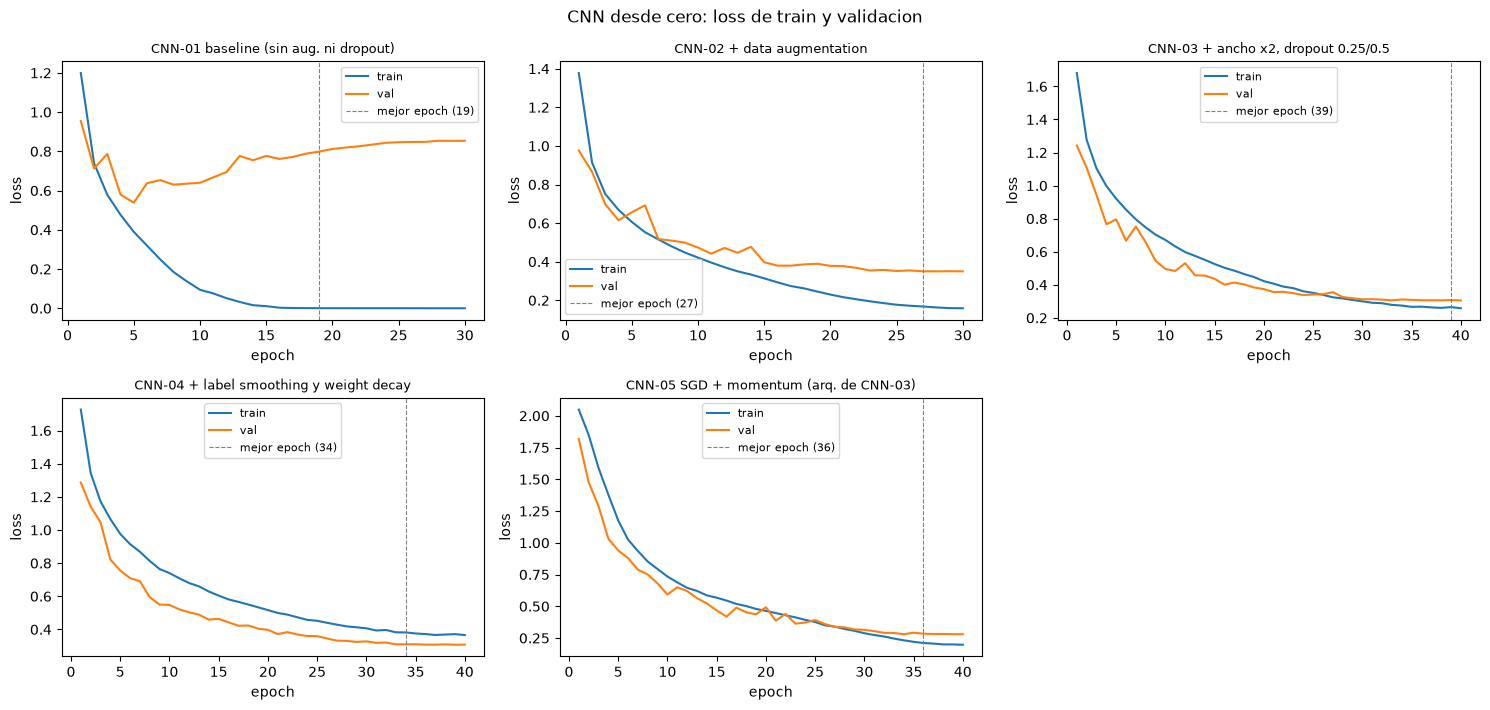

In [18]:
plot_loss_curves(results_cnn, "CNN desde cero: loss de train y validacion", "curvas_cnn.png")

**Observaciones (CNN desde cero).** CNN-01, sin augmentation ni dropout, es el caso claro de **overfitting**: su train loss llega a ≈ 0.000 mientras que su val loss, mínima en la epoch 5 (0.538), sube hasta 0.854 al final; la accuracy de validación se estanca en 85.92 %. Agregar **augmentation** (CNN-02) baja la val loss mínima a 0.350 y sube la accuracy a 89.26 % (+3.3 pts), con una brecha train-val de 0.19. Ensanchar la red y agregar dropout (CNN-03) llega a 90.52 %, con una brecha de solo 0.05. **Label smoothing + weight decay (CNN-04) da la mejor accuracy de validación, 91.36 %** (mejor epoch 34 de 40). SGD con momentum (CNN-05) llega a 91.28 % con la menor val loss (0.280). Con las regularizaciones más fuertes la train loss (medida con augmentation y dropout activos) queda por encima de la de validación (0.366 frente a 0.309 en CNN-04) y las curvas siguen mejorando al final: hay algo de *underfitting*, por lo que más epochs probablemente mejorarían un poco estas iteraciones.

### 4.4 VGG-16 como extractor de características

Se carga VGG-16 con pesos de ImageNet, **se congelan los 5 bloques convolucionales** y se reemplaza `classifier[6]` por `Linear(4096, 10)`. Solo se entrenan los parámetros del clasificador: como el enunciado lo pide, en las iteraciones principales el `classifier` completo (`fc6`, `fc7` y la capa nueva); además se prueba un *linear probe* (solo la capa nueva). Las iteraciones varían el learning rate, qué parte del clasificador se entrena y el uso de augmentation.

In [19]:
BASE_FE = {
    "family": "vgg", "unfrozen_blocks": [], "train_full_classifier": True, "optimizer": "adamw",
    "lr_head": 1e-4, "lr_backbone": 0.0, "weight_decay": 1e-2, "label_smoothing": 0.0, "augment": True,
    "epochs": 8, "batch_size": 128, "seed": 42,
}


def cfg_fe(name, **overrides):
    """Crea la configuracion de una iteracion del extractor de caracteristicas a partir de BASE_FE."""
    return {**BASE_FE, **overrides, "name": name}


fe_configs = [
    cfg_fe("FE-01 linear probe (solo classifier[6]), lr 1e-3", train_full_classifier=False, lr_head=1e-3),
    cfg_fe("FE-02 classifier completo, lr 1e-4"),
    cfg_fe("FE-03 classifier completo, lr 1e-3", lr_head=1e-3),
    cfg_fe("FE-04 classifier completo, lr 1e-4, sin augmentation", augment=False),
]
print("Iteraciones configuradas (extractor):", len(fe_configs))

Iteraciones configuradas (extractor): 4


In [20]:
results_fe = [run_iteration(cfg, f"fe_{i + 1:02d}", train_idx) for i, cfg in enumerate(fe_configs)]
results_df_fe = results_table(results_fe)
display(results_df_fe.drop(columns=["hiperparametros"]).round(4))

[cache] fe_01: FE-01 linear probe (solo classifier[6]), lr 1e-3
[cache] fe_02: FE-02 classifier completo, lr 1e-4
[cache] fe_03: FE-03 classifier completo, lr 1e-3
[cache] fe_04: FE-04 classifier completo, lr 1e-4, sin augmentation


,iteracion,capas congeladas,val_loss,val_acc,val_prec,val_rec,val_f1,mejor_epoch,epochs,params_total,params_entrenables,s/epoch,tiempo_total_s,mem_pico_MB
0,"FE-01 linear probe (solo classifier[6]), lr 1e-3","bloques 1,2,3,4,5 congelados; solo classifier[...",0.4356,0.8452,0.8451,0.8452,0.8441,6,8,134301514,40970,23.9046,212.0592,2752.2847
1,"FE-02 classifier completo, lr 1e-4","bloques 1,2,3,4,5 congelados; classifier compl...",0.2973,0.8950,0.8951,0.8950,0.8949,7,8,134301514,119586826,31.0886,269.9090,4120.3784
2,"FE-03 classifier completo, lr 1e-3","bloques 1,2,3,4,5 congelados; classifier compl...",0.3299,0.8934,0.8938,0.8934,0.8932,7,8,134301514,119586826,31.2556,271.0706,4120.3784
3,"FE-04 classifier completo, lr 1e-4, sin augmen...","bloques 1,2,3,4,5 congelados; classifier compl...",0.3780,0.9046,0.9048,0.9046,0.9046,8,8,134301514,119586826,30.9048,268.3408,4120.3784


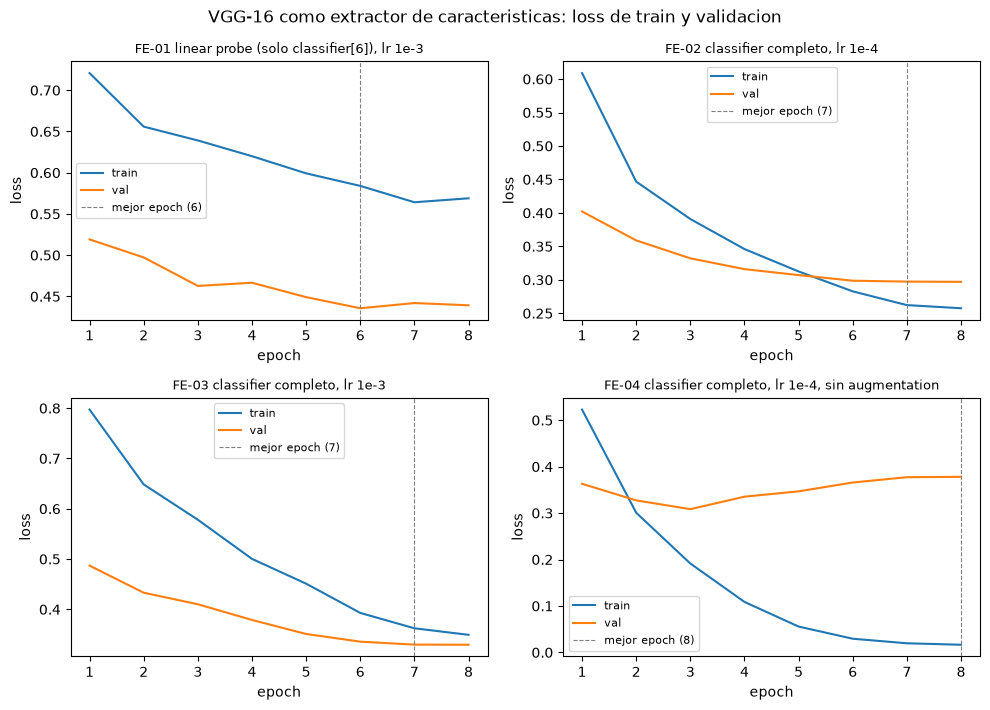

In [21]:
plot_loss_curves(results_fe, "VGG-16 como extractor de caracteristicas: loss de train y validacion", "curvas_fe.png", ncols=2)

**Observaciones (VGG-16 como extractor).** Con solo **40,970 parámetros entrenables** (*linear probe*, FE-01) las características congeladas ya alcanzan 84.52 % de accuracy de validación, lo que muestra que son útiles incluso con imágenes de 32×32 escaladas. Entrenar el `classifier` completo mejora a 89.50 % (FE-02, lr 1e-4) y 89.34 % (FE-03, lr 1e-3; con mayor val loss, 0.330 frente a 0.297, un lr alto vuelve el entrenamiento más ruidoso). FE-04, sin augmentation, obtiene la **mejor accuracy de validación (90.46 %)** pero es la única iteración con **overfitting claro**: train loss 0.016 frente a val loss 0.378, con mínimo de 0.308 en la epoch 3 y aumento posterior. Con augmentation, FE-02 y FE-03 no muestran brecha, pero siguen mejorando en la epoch 8: como el backbone está congelado y no se adapta a los recortes y flips, el clasificador de 120 M de parámetros converge más lento en 8 epochs. La iteración se eligió por accuracy de validación (criterio definido de antemano), aunque su val loss no sea la mejor.

### 4.5 VGG-16 con fine-tuning

Partiendo del mismo modelo preentrenado se **descongelan uno o más bloques convolucionales superiores** y se entrenan junto con el clasificador, con **learning rate menor para el backbone que para el clasificador** mediante `param_groups`. Las iteraciones varían el **número de bloques descongelados** (5; 4-5; 3-5) y el **learning rate del backbone**:

- FT-01 a FT-03: `lr_head = 1e-4` y `lr_backbone = 1e-5`, variando los bloques (5; 4-5; 3-5).
- FT-04 y FT-05: **controles** con `lr_backbone` igual (1e-4) y mayor (1e-3) que `lr_head = 1e-4`. No cumplen la restricción del enunciado (backbone con lr menor que el clasificador), por lo que **se reportan pero se excluyen de la selección de la mejor configuración**; sirven para estudiar el efecto de un lr alto en el backbone (*catastrophic forgetting*).
- FT-06 y FT-07: `lr_head` más alto (1e-3 y 5e-4) con `lr_backbone` 10 veces menor (1e-4 y 5e-5), sobre bloques 4-5 y 3-5, que sí cumplen la restricción.

In [22]:
BASE_FT = {
    "family": "vgg", "unfrozen_blocks": [5], "train_full_classifier": True, "optimizer": "adamw",
    "lr_head": 1e-4, "lr_backbone": 1e-5, "weight_decay": 1e-2, "label_smoothing": 0.0, "augment": True,
    "epochs": 8, "batch_size": 128, "seed": 42,
}


def cfg_ft(name, **overrides):
    """Crea la configuracion de una iteracion de fine-tuning a partir de BASE_FT."""
    return {**BASE_FT, **overrides, "name": name}


ft_configs = [
    cfg_ft("FT-01 bloque 5, lr backbone 1e-5", unfrozen_blocks=[5]),
    cfg_ft("FT-02 bloques 4-5, lr backbone 1e-5", unfrozen_blocks=[4, 5]),
    cfg_ft("FT-03 bloques 3-5, lr backbone 1e-5", unfrozen_blocks=[3, 4, 5]),
    cfg_ft("FT-04 bloques 4-5, lr backbone 1e-4", unfrozen_blocks=[4, 5], lr_backbone=1e-4),
    cfg_ft("FT-05 bloques 4-5, lr backbone 1e-3 (alto)", unfrozen_blocks=[4, 5], lr_backbone=1e-3),
    cfg_ft("FT-06 bloques 4-5, lr backbone 1e-4, lr head 1e-3", unfrozen_blocks=[4, 5], lr_backbone=1e-4, lr_head=1e-3),
    cfg_ft("FT-07 bloques 3-5, lr backbone 5e-5, lr head 5e-4", unfrozen_blocks=[3, 4, 5], lr_backbone=5e-5, lr_head=5e-4),
]
print("Iteraciones configuradas (fine-tuning):", len(ft_configs))

Iteraciones configuradas (fine-tuning): 7


In [23]:
results_ft = [run_iteration(cfg, f"ft_{i + 1:02d}", train_idx) for i, cfg in enumerate(ft_configs)]
results_df_ft = results_table(results_ft)
display(results_df_ft.drop(columns=["hiperparametros"]).round(4))

[cache] ft_01: FT-01 bloque 5, lr backbone 1e-5
[cache] ft_02: FT-02 bloques 4-5, lr backbone 1e-5
[cache] ft_03: FT-03 bloques 3-5, lr backbone 1e-5
[cache] ft_04: FT-04 bloques 4-5, lr backbone 1e-4
[cache] ft_05: FT-05 bloques 4-5, lr backbone 1e-3 (alto)
[cache] ft_06: FT-06 bloques 4-5, lr backbone 1e-4, lr head 1e-3
[cache] ft_07: FT-07 bloques 3-5, lr backbone 5e-5, lr head 5e-4


,iteracion,capas congeladas,val_loss,val_acc,val_prec,val_rec,val_f1,mejor_epoch,epochs,params_total,params_entrenables,s/epoch,tiempo_total_s,mem_pico_MB
0,"FT-01 bloque 5, lr backbone 1e-5","bloques 1,2,3,4 congelados; classifier complet...",0.2526,0.9180,0.9180,0.9180,0.9179,6,8,134301514,126666250,35.0761,301.5348,4202.8950
1,"FT-02 bloques 4-5, lr backbone 1e-5","bloques 1,2,3 congelados; classifier completo ...",0.2067,0.9352,0.9351,0.9352,0.9350,6,8,134301514,132566026,44.1918,374.9614,4268.9136
2,"FT-03 bloques 3-5, lr backbone 1e-5","bloques 1,2 congelados; classifier completo en...",0.1933,0.9404,0.9404,0.9404,0.9404,8,8,134301514,134041354,55.1149,462.4546,4287.7974
3,"FT-04 bloques 4-5, lr backbone 1e-4","bloques 1,2,3 congelados; classifier completo ...",0.2002,0.9494,0.9497,0.9494,0.9495,6,8,134301514,132566026,44.9474,381.1014,4268.9136
4,"FT-05 bloques 4-5, lr backbone 1e-3 (alto)","bloques 1,2,3 congelados; classifier completo ...",0.2746,0.9134,0.9135,0.9134,0.9133,8,8,134301514,132566026,47.5615,403.1372,4268.9136
5,"FT-06 bloques 4-5, lr backbone 1e-4, lr head 1e-3","bloques 1,2,3 congelados; classifier completo ...",0.2616,0.9380,0.9386,0.9380,0.9381,6,8,134301514,132566026,44.3758,375.9029,4268.9136
6,"FT-07 bloques 3-5, lr backbone 5e-5, lr head 5e-4","bloques 1,2 congelados; classifier completo en...",0.2092,0.9496,0.9498,0.9496,0.9497,8,8,134301514,134041354,55.1085,462.2702,4287.7974


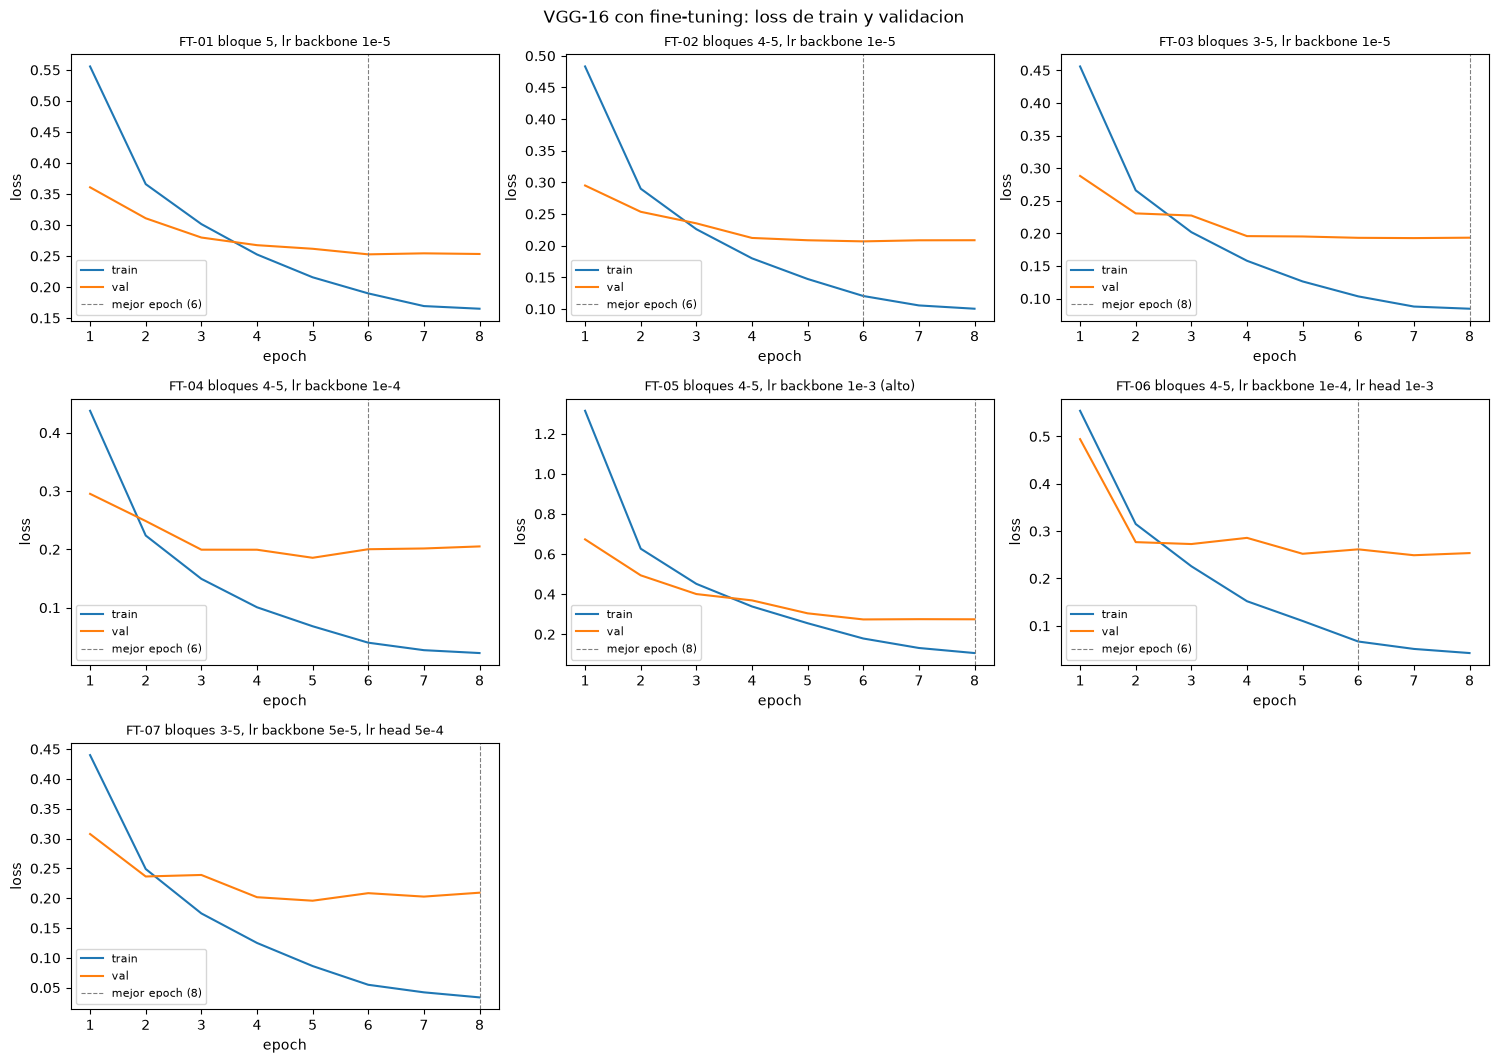

In [24]:
plot_loss_curves(results_ft, "VGG-16 con fine-tuning: loss de train y validacion", "curvas_ft.png")

**Observaciones (VGG-16 con fine-tuning).** Con lr del backbone 1e-5 y del clasificador 1e-4, descongelar más bloques mejora de forma monótona pero con rendimientos decrecientes: bloque 5 → 91.80 %; bloques 4-5 → 93.52 % (+1.72 pts); bloques 3-5 → 94.04 % (+0.52 pts), mientras el tiempo por epoch sube de 35.1 a 44.2 y a 55.1 s. Subir el lr ayuda hasta cierto punto: FT-07 (bloques 3-5, backbone 5e-5, clasificador 5e-4) es la **mejor iteración que cumple la restricción, con 94.96 % de accuracy de validación**, mientras que FT-06 (bloques 4-5, backbone 1e-4, clasificador 1e-3) llega a 93.80 %. Los **controles** FT-04 (backbone = clasificador = 1e-4) y FT-05 (backbone 1e-3 > clasificador 1e-4), que no cumplen la restricción del enunciado y no participan en la selección, dan 94.94 % y 91.34 %: con lr igual el resultado es equivalente al de FT-07, pero con el backbone 10 veces más rápido que el clasificador (FT-05) se produce *catastrophic forgetting*: su accuracy de validación tras la primera epoch es solo 77.2 % (frente a 90.4 % en FT-04 y 89.9 % en FT-07) porque los gradientes grandes de la capa nueva y aleatoria, con un lr alto, degradan las características preentrenadas; se recupera parcialmente pero termina 3.6 pts por debajo y peor incluso que FT-01. Respecto al **overfitting**, en FT-07 la train loss termina en 0.034 frente a una val loss de 0.209 (mínima 0.196 en la epoch 5, con leve aumento posterior), un sobreajuste leve sin caída de la accuracy; en FT-01 a FT-03 la brecha es ≈ 0.09-0.11 sin aumento de la val loss.

### 4.6 Mejor configuración de cada modelo y evaluación única en test

La mejor iteración de cada modelo según accuracy de validación (entre las que cumplen las restricciones del enunciado) se evalúa **una única vez** sobre el conjunto de test oficial (10,000 imágenes), cargando los pesos de su mejor epoch. Se reportan accuracy, precision, recall y F1 (macro) y la matriz de confusión de cada modelo.

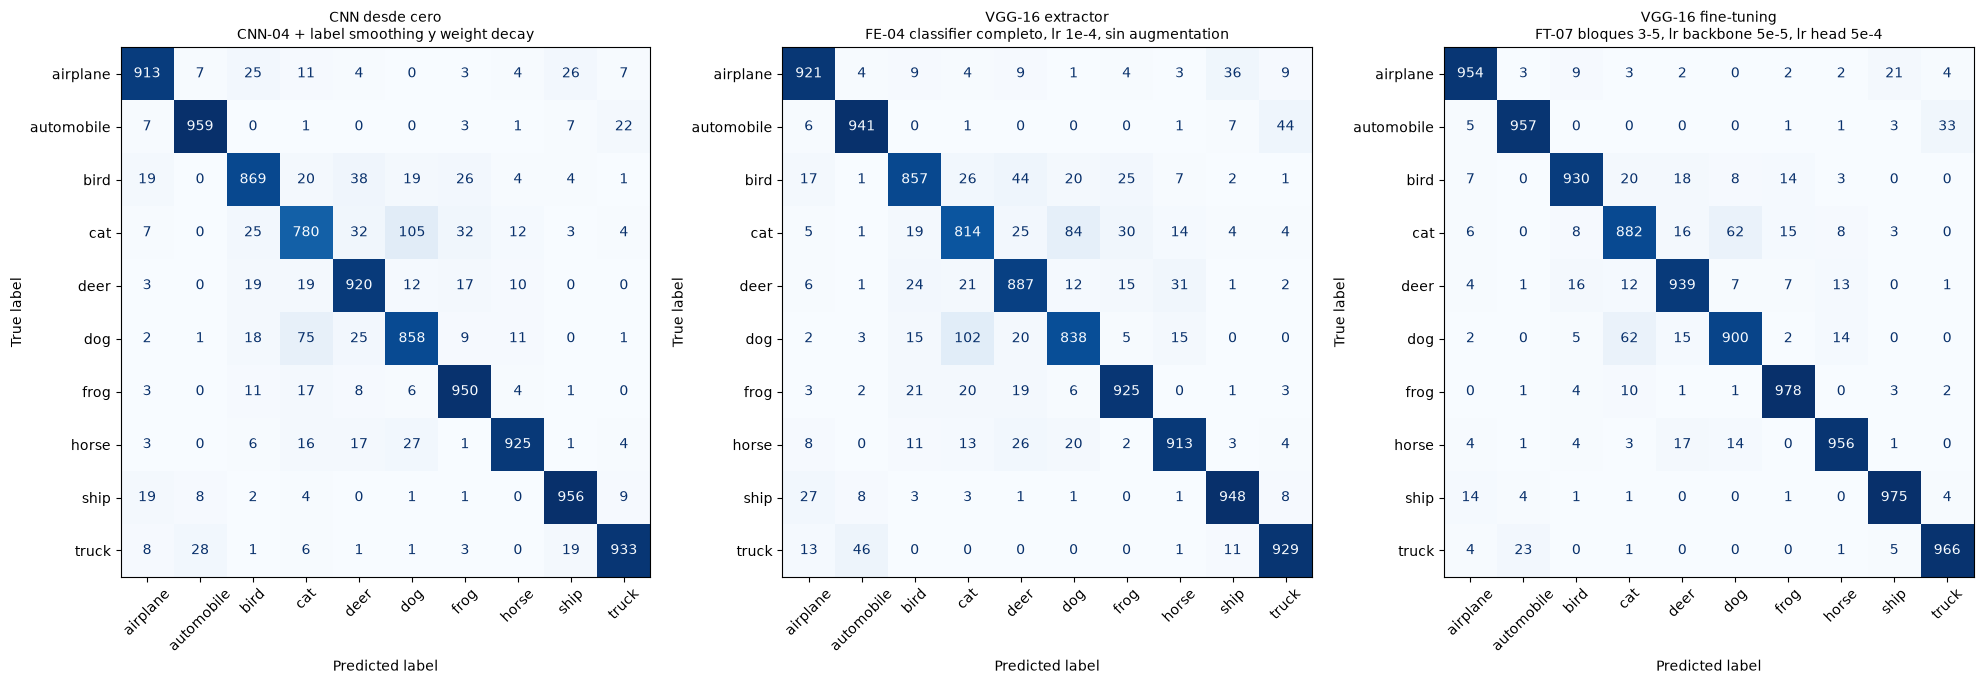

,modelo,iteracion,test_accuracy,test_precision,test_recall,test_f1,val_accuracy
0,CNN desde cero,CNN-04 + label smoothing y weight decay,0.9063,0.9063,0.9063,0.9061,0.9136
1,VGG-16 extractor,"FE-04 classifier completo, lr 1e-4, sin augmen...",0.8973,0.8973,0.8973,0.8972,0.9046
2,VGG-16 fine-tuning,"FT-07 bloques 3-5, lr backbone 5e-5, lr head 5e-4",0.9437,0.9436,0.9437,0.9436,0.9496


In [25]:
FAMILIES = {
    "CNN desde cero": ("cnn", cnn_configs, results_cnn),
    "VGG-16 extractor": ("fe", fe_configs, results_fe),
    "VGG-16 fine-tuning": ("ft", ft_configs, results_ft),
}

best = {}   # nombre del modelo -> {"result", "cfg", "run_id", "test"}
for model_name, (prefix, configs, results) in FAMILIES.items():
    # Solo son elegibles las iteraciones que cumplen el enunciado: en fine-tuning, lr del backbone < lr del clasificador
    eligible = [r for r, c in zip(results, configs) if not c.get("unfrozen_blocks") or c["lr_backbone"] < c["lr_head"]]
    r = pick_best(eligible)
    i = results.index(r)
    best[model_name] = {"result": r, "cfg": configs[i], "run_id": f"{prefix}_{i + 1:02d}"}
    cleanup_checkpoints([f"{prefix}_{j + 1:02d}" for j in range(len(configs))], best[model_name]["run_id"])

test_rows, per_class = [], {}
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, (model_name, b) in zip(axes, best.items()):
    model = load_best_model(b["cfg"], b["run_id"])
    test = evaluate(model, X_test, y_test, PREP[b["cfg"]["family"]])   # unica evaluacion en test
    b["test"] = {k: float(test[k]) for k in ("accuracy", "precision", "recall", "f1")}
    b["y_true"], b["y_pred"] = test["y_true"], test["y_pred"]
    test_rows.append({"modelo": model_name, "iteracion": b["result"]["name"], **{f"test_{k}": v for k, v in b["test"].items()},
                      "val_accuracy": b["result"]["val_accuracy"]})
    cm = confusion_matrix(test["y_true"], test["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{model_name}\n{b['result']['name']}", fontsize=10)
    per_class[model_name] = cm.diagonal() / cm.sum(axis=1)  # recall por clase
    del model
    gc.collect(); torch.cuda.empty_cache()
plt.tight_layout()
plt.savefig(Path(CONFIG["figures_dir"]) / "matrices_confusion.png", bbox_inches="tight")
plt.show()

test_df = pd.DataFrame(test_rows)
display(test_df.round(4))

In [26]:
# Recall por clase y pares de clases mas confundidos (fuera de la diagonal) de cada modelo
display(pd.DataFrame(per_class, index=CLASSES).round(3))

conf_rows = []
for model_name, b in best.items():
    cm = confusion_matrix(b["y_true"], b["y_pred"])
    off = cm.copy(); np.fill_diagonal(off, 0)
    pairs = [(CLASSES[i], CLASSES[j], int(off[i, j])) for i in range(10) for j in range(10) if i != j]
    for real, pred, n in sorted(pairs, key=lambda t: -t[2])[:5]:
        conf_rows.append({"modelo": model_name, "real": real, "predicho": pred, "errores": n})
display(pd.DataFrame(conf_rows))

,CNN desde cero,VGG-16 extractor,VGG-16 fine-tuning
airplane,0.913,0.921,0.954
automobile,0.959,0.941,0.957
bird,0.869,0.857,0.930
cat,0.780,0.814,0.882
deer,0.920,0.887,0.939
dog,0.858,0.838,0.900
frog,0.950,0.925,0.978
horse,0.925,0.913,0.956
ship,0.956,0.948,0.975
truck,0.933,0.929,0.966


,modelo,real,predicho,errores
0,CNN desde cero,cat,dog,105
1,CNN desde cero,dog,cat,75
2,CNN desde cero,bird,deer,38
3,CNN desde cero,cat,deer,32
4,CNN desde cero,cat,frog,32
5,VGG-16 extractor,dog,cat,102
6,VGG-16 extractor,cat,dog,84
7,VGG-16 extractor,truck,automobile,46
8,VGG-16 extractor,automobile,truck,44
9,VGG-16 extractor,bird,deer,44


**Observaciones (test).** Evaluados una sola vez en test: CNN 90.63 % de accuracy (F1 0.9061), extractor 89.73 % (F1 0.8972) y fine-tuning (FT-07) **94.37 %** (F1 0.9436). La accuracy de test es entre 0.6 y 0.7 pts menor que la de validación (91.36, 90.46 y 94.96 %), lo esperable por el leve optimismo de haber elegido la mejor iteración y epoch sobre validación, sin señales de sobreajuste a ese conjunto. Precision y recall macro son casi idénticas a la accuracy porque las clases están balanceadas.

**Matrices de confusión.** La confusión dominante en los tres modelos es **gato ↔ perro** (CNN: 105 + 75 errores; extractor: 102 + 84; fine-tuning: 62 + 62), y gato es la clase con menor recall en los tres (0.780, 0.814 y 0.882), seguida de perro y pájaro. En los modelos basados en VGG-16 aparece además **automóvil ↔ camión** (44 + 46 en el extractor; 33 + 23 en fine-tuning), que la CNN confunde menos (recall de automóvil 0.959, el más alto de sus clases); en CNN y extractor **pájaro → venado** (38 y 44), y en fine-tuning **avión → barco** (21). De las hipótesis de la Sección 2.3, gato-perro y automóvil-camión se confirman, avión-barco solo en fine-tuning, y venado-caballo no aparece entre los 5 errores más frecuentes de ningún modelo.

### 4.7 Experimento adicional: efecto de la cantidad de datos

Se reentrenan **las mejores configuraciones de los tres modelos** con solo el **10 %** de las imágenes de entrenamiento (4,500 imágenes, **450 por clase**, muestreo estratificado) y se evalúan sobre el mismo conjunto de test. Se mantienen exactamente los mismos hiperparámetros y el mismo número de epochs que en el experimento con 100 %; la validación completa de 5,000 imágenes se usa para elegir la mejor epoch en todos los casos.

In [27]:
low_idx, _ = train_test_split(
    train_idx, train_size=CONFIG["low_data_fraction"], random_state=CONFIG["random_state"],
    stratify=train_targets[train_idx],
)
print("Imagenes de train con 10%:", len(low_idx), "| por clase:", np.bincount(train_targets[low_idx]))

low_rows, low_results = [], {}
for model_name, b in best.items():
    cfg_low = {**b["cfg"], "name": b["cfg"]["name"] + " [10% datos]"}
    run_id = "low_" + b["run_id"]
    r = run_iteration(cfg_low, run_id, low_idx, need_ckpt=True)
    low_results[model_name] = r
    model = load_best_model(cfg_low, run_id)
    test = evaluate(model, X_test, y_test, PREP[cfg_low["family"]])
    b["test_low"] = {k: float(test[k]) for k in ("accuracy", "precision", "recall", "f1")}
    low_rows.append({
        "modelo": model_name,
        "test_acc_100%": b["test"]["accuracy"], "test_f1_100%": b["test"]["f1"],
        "test_acc_10%": b["test_low"]["accuracy"], "test_f1_10%": b["test_low"]["f1"],
        "caida_acc (pts)": (b["test"]["accuracy"] - b["test_low"]["accuracy"]) * 100,
        "caida_acc (%)": (1 - b["test_low"]["accuracy"] / b["test"]["accuracy"]) * 100,
        "caida_f1 (pts)": (b["test"]["f1"] - b["test_low"]["f1"]) * 100,
        "mejor_epoch_10%": r["best_epoch"], "tiempo_total_10%_s": r["total_time_s"],
    })
    del model
    gc.collect(); torch.cuda.empty_cache()
    p = Path(CONFIG["checkpoints_dir"]) / f"{run_id}.pt"
    if p.exists():
        p.unlink()

low_df = pd.DataFrame(low_rows)
display(low_df.round(4))

Imagenes de train con 10%: 4500 | por clase: [450 450 450 450 450 450 450 450 450 450]
=== low_cnn_04: CNN-04 + label smoothing y weight decay [10% datos] | params=2,197,706 | entrenables=2,197,706


  epoch 01/40 train_loss=2.2628 val_loss=1.9562 val_acc=0.2522 val_f1=0.2276 (0.5s)


  epoch 02/40 train_loss=1.9564 val_loss=1.8271 val_acc=0.3250 val_f1=0.3078 (0.3s)


  epoch 03/40 train_loss=1.8456 val_loss=1.8105 val_acc=0.3334 val_f1=0.3131 (0.3s)


  epoch 04/40 train_loss=1.7635 val_loss=1.7261 val_acc=0.3442 val_f1=0.3180 (0.3s)


  epoch 05/40 train_loss=1.7271 val_loss=1.5507 val_acc=0.4260 val_f1=0.3988 (0.3s)


... (52 outputs left out)

  epoch 07/8 train_loss=0.0593 val_loss=0.4184 val_acc=0.8954 val_f1=0.8954 (5.4s)


  epoch 08/8 train_loss=0.0485 val_loss=0.4183 val_acc=0.8958 val_f1=0.8958 (5.4s)


  -> mejor epoch 8: val_acc=0.8958 val_f1=0.8958 | tiempo total=64s | pico GPU=4162 MB


,modelo,test_acc_100%,test_f1_100%,test_acc_10%,test_f1_10%,caida_acc (pts),caida_acc (%),caida_f1 (pts),mejor_epoch_10%,tiempo_total_10%_s
0,CNN desde cero,0.9063,0.9061,0.6943,0.6878,21.20,23.3918,21.8313,39,17.9422
1,VGG-16 extractor,0.8973,0.8972,0.8433,0.8432,5.40,6.0181,5.3977,8,43.0515
2,VGG-16 fine-tuning,0.9437,0.9436,0.8911,0.8909,5.26,5.5738,5.2730,8,63.9596


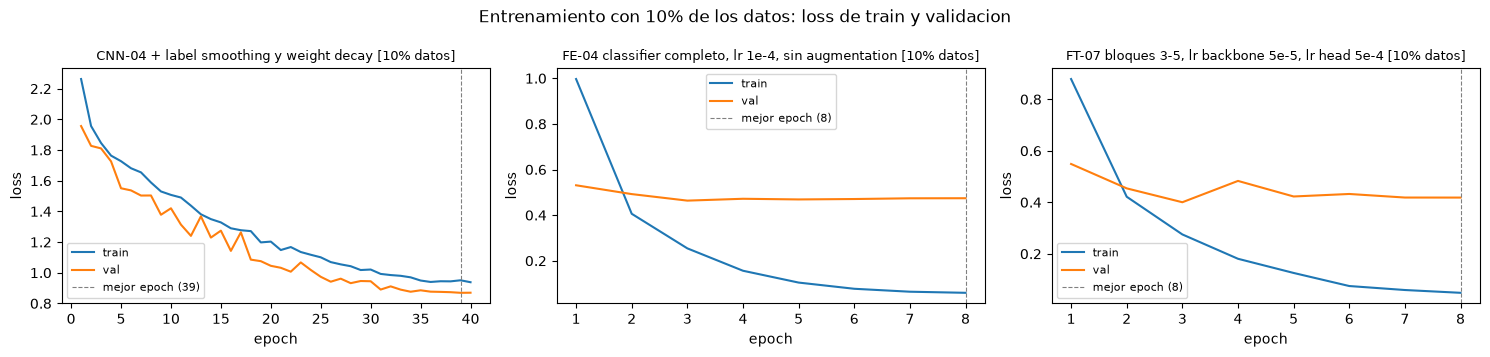

In [28]:
plot_loss_curves(list(low_results.values()), "Entrenamiento con 10% de los datos: loss de train y validacion", "curvas_10pct.png")

**Observaciones (10 % de los datos).** Con 4,500 imágenes de entrenamiento (450 por clase), la accuracy de test cae de 90.63 % a 69.43 % en la **CNN desde cero (−21.2 pts, −23.4 % relativo)**, de 89.73 % a 84.33 % en el **extractor (−5.4 pts, −6.0 %)** y de 94.37 % a 89.11 % en el **fine-tuning (−5.3 pts, −5.6 %)**. El orden de los modelos cambia: con el 100 % de los datos la CNN supera ligeramente al extractor, mientras que con el 10 % el extractor la supera por 14.9 pts y el fine-tuning por 19.7 pts. Los modelos VGG-16 muestran sobreajuste en este régimen (train loss ≈ 0.05-0.06 frente a val loss 0.42-0.47), mientras que la CNN queda en *underfitting* (train loss 0.94 al final, con la accuracy de validación aún subiendo): parte de su caída se debe a que con el mismo número de epochs recibe 10 veces menos actualizaciones. Además, la validación de 5,000 imágenes usada para elegir la mejor epoch es mayor que el propio conjunto de entrenamiento, lo que favorece levemente a los tres modelos.

## 5. Comparación de rendimiento y recursos

Con la mejor configuración de cada modelo se construye la tabla comparativa. Metodología de las columnas de costo:

- **MACs/FLOPs de inferencia por imagen:** conteo analítico por hooks (`layer_macs`, solo `Conv2d` y `Linear`), verificado contra `torchinfo` y `FlopCounterMode`. FLOPs = 2 × MACs.
- **Latencia por imagen en GPU:** modelo en modo `eval()` con `torch.no_grad()`, **fp32**, con *warm-up*, `torch.cuda.synchronize()` antes y después del bucle cronometrado y promedio de 100 iteraciones. Se mide con **batch = 1** (latencia de una petición individual) y con **batch = 128** (tiempo por imagen amortizado, throughput de servidor).
- **Costo de entrenamiento:** tiempo promedio por epoch (solo la fase de entrenamiento), epochs hasta la mejor accuracy de validación, tiempo total (incluye validación) y memoria pico de GPU medidos durante el entrenamiento real de la iteración.
- **FLOPs totales de entrenamiento (estimación):** `imágenes × epochs × (FLOPs forward + FLOPs backward)` por imagen. El backward de una capa entrenable cuesta ≈ 2× su forward (gradiente respecto a la entrada + gradiente respecto a los pesos); el de la **primera** capa entrenable solo necesita el gradiente de los pesos (1×); las capas congeladas *posteriores* a alguna entrenable solo propagan el gradiente de entrada (1×); y las capas congeladas *anteriores* a toda capa entrenable **no hacen backward** (0×). Se excluyen las operaciones de validación, el optimizador y la augmentation.

In [29]:
@torch.no_grad()
def measure_latency_ms(model, shape, batch_size, n_warmup=20, n_iters=100):
    """Latencia media por imagen (ms) en GPU: warm-up, sincronizacion antes y despues, promedio de n_iters."""
    model.eval()
    x = torch.randn(batch_size, *shape, device=DEVICE)
    for _ in range(n_warmup):
        model(x)
    sync(); t0 = time.perf_counter()
    for _ in range(n_iters):
        model(x)
    sync()
    return (time.perf_counter() - t0) / n_iters / batch_size * 1000


def training_macs_per_image(records):
    """MACs de forward y backward por imagen segun que capas Conv/Linear son entrenables (ver reglas arriba)."""
    fwd = sum(m for _, m, _ in records)
    bwd, seen = 0, False
    for _, macs, trainable in records:
        if trainable and not seen:
            bwd += macs          # primera capa entrenable: solo gradiente de los pesos
            seen = True
        elif seen:
            bwd += 2 * macs if trainable else macs   # entrenable: dW + dX ; congelada: solo dX
    return fwd, bwd


cost_rows = []
for model_name, b in best.items():
    cfg, r = b["cfg"], b["result"]
    shape = input_shape(cfg)
    model = build_model(cfg).to(DEVICE)   # con los flags requires_grad de esta iteracion

    recs = layer_macs(model, shape)
    macs_hooks = sum(m for _, m, _ in recs)
    info = summary(model, input_size=(1, *shape), verbose=0, device=DEVICE)
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        model.eval()(torch.zeros(1, *shape, device=DEVICE))
    b["macs_check"] = {"hooks": macs_hooks, "torchinfo": info.total_mult_adds, "flop_counter": fc.get_total_flops() / 2}

    fwd_macs, bwd_macs = training_macs_per_image(recs)
    train_flops_img = 2 * (fwd_macs + bwd_macs)
    b["cost"] = {
        "MACs inferencia": macs_hooks,
        "FLOPs inferencia": 2 * macs_hooks,
        "FLOPs backward/img": 2 * bwd_macs,
        "lat_bs1_ms": measure_latency_ms(model, shape, 1),
        "lat_bs128_ms_img": measure_latency_ms(model, shape, 128),
        "FLOPs entren. hasta mejor epoch": train_flops_img * r["n_train"] * r["best_epoch"],
        "FLOPs entren. total": train_flops_img * r["n_train"] * r["epochs"],
    }
    del model, info
    gc.collect(); torch.cuda.empty_cache()

# Verificacion cruzada de las tres formas de contar MACs
display(pd.DataFrame({m: {k: f"{v / 1e6:.2f} M" for k, v in b["macs_check"].items()} for m, b in best.items()}).T)

,hooks,torchinfo,flop_counter
CNN desde cero,153.82 M,153.82 M,153.82 M
VGG-16 extractor,5130.72 M,5135.16 M,5130.72 M
VGG-16 fine-tuning,5130.72 M,5135.16 M,5130.72 M


In [30]:
comparison_df = pd.DataFrame([{
    "modelo": name,
    "iteracion": b["result"]["name"],
    "params_total": b["result"]["params_total"],
    "params_entrenables": b["result"]["params_trainable"],
    "MACs inferencia (M)": b["cost"]["MACs inferencia"] / 1e6,
    "FLOPs inferencia (M)": b["cost"]["FLOPs inferencia"] / 1e6,
    "latencia bs=1 (ms)": b["cost"]["lat_bs1_ms"],
    "latencia bs=128 (ms/img)": b["cost"]["lat_bs128_ms_img"],
    "s/epoch": b["result"]["mean_epoch_s"],
    "epochs hasta mejor val": b["result"]["best_epoch"],
    "tiempo total (s)": b["result"]["total_time_s"],
    "mem. pico GPU (MB)": b["result"]["peak_mem_mb"],
    "FLOPs entren. total (T)": b["cost"]["FLOPs entren. total"] / 1e12,
    "FLOPs entren. hasta mejor (T)": b["cost"]["FLOPs entren. hasta mejor epoch"] / 1e12,
    "test_acc": b["test"]["accuracy"], "test_prec": b["test"]["precision"],
    "test_rec": b["test"]["recall"], "test_f1": b["test"]["f1"],
    "test_acc 10% datos": b["test_low"]["accuracy"], "test_f1 10% datos": b["test_low"]["f1"],
} for name, b in best.items()]).set_index("modelo")

display(comparison_df.T.round(4))
print("Hardware:", HARDWARE)

modelo,CNN desde cero,VGG-16 extractor,VGG-16 fine-tuning
iteracion,CNN-04 + label smoothing y weight decay,"FE-04 classifier completo, lr 1e-4, sin augmen...","FT-07 bloques 3-5, lr backbone 5e-5, lr head 5e-4"
params_total,2197706,134301514,134301514
params_entrenables,2197706,119586826,134041354
MACs inferencia (M),153.815552,5130.723328,5130.723328
FLOPs inferencia (M),307.631104,10261.446656,10261.446656
latencia bs=1 (ms),0.708188,2.380741,2.409114
latencia bs=128 (ms/img),0.032465,0.836706,0.83972
s/epoch,3.721645,30.904796,55.108496
epochs hasta mejor val,34,8,8
tiempo total (s),153.850468,268.340764,462.270245


Hardware: {'GPU': 'NVIDIA GeForce RTX 3060 Ti', 'VRAM (GB)': 8.0, 'CPU': 'AMD Ryzen 5 7600 6-Core Processor', 'Nucleos logicos': 12, 'PyTorch': '2.14.0+cu126', 'CUDA (build)': '12.6'}


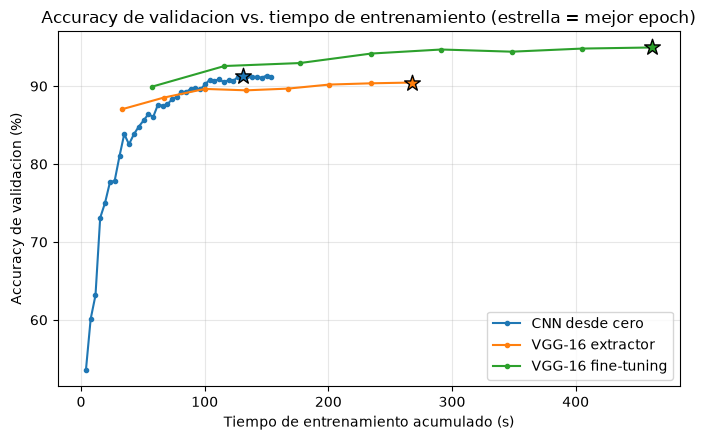

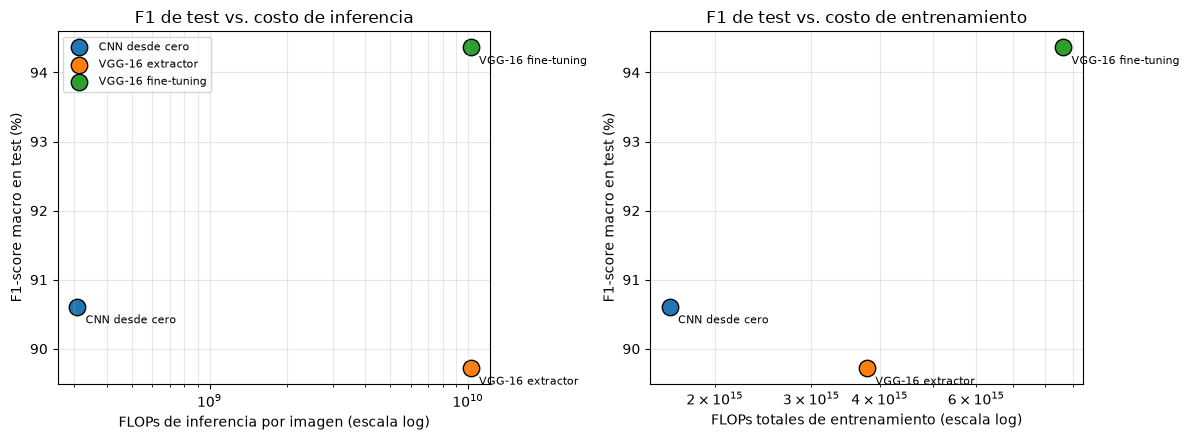

In [31]:
colors = {"CNN desde cero": "tab:blue", "VGG-16 extractor": "tab:orange", "VGG-16 fine-tuning": "tab:green"}

# Grafica 1: accuracy de validacion vs tiempo de entrenamiento acumulado
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, b in best.items():
    h = b["result"]["history"]
    t = np.cumsum(np.array(h["train_time"]) + np.array(h["val_time"]))
    ax.plot(t, np.array(h["val_acc"]) * 100, marker="o", ms=3, color=colors[name], label=name)
    be = b["result"]["best_epoch"] - 1
    ax.scatter(t[be], h["val_acc"][be] * 100, s=140, marker="*", color=colors[name], edgecolor="black", zorder=3)
ax.set_xlabel("Tiempo de entrenamiento acumulado (s)")
ax.set_ylabel("Accuracy de validacion (%)")
ax.set_title("Accuracy de validacion vs. tiempo de entrenamiento (estrella = mejor epoch)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(Path(CONFIG["figures_dir"]) / "acc_vs_tiempo.png", bbox_inches="tight")
plt.show()

# Grafica 2: F1 de test vs costo computacional (inferencia y entrenamiento), eje x logaritmico
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, key, xlabel in ((axes[0], "FLOPs inferencia", "FLOPs de inferencia por imagen"),
                        (axes[1], "FLOPs entren. total", "FLOPs totales de entrenamiento")):
    for name, b in best.items():
        ax.scatter(b["cost"][key], b["test"]["f1"] * 100, s=140, color=colors[name], edgecolor="black", label=name)
        ax.annotate(name, (b["cost"][key], b["test"]["f1"] * 100), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel(xlabel + " (escala log)"); ax.set_ylabel("F1-score macro en test (%)")
    ax.grid(alpha=0.3, which="both")
axes[0].set_title("F1 de test vs. costo de inferencia"); axes[1].set_title("F1 de test vs. costo de entrenamiento")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(Path(CONFIG["figures_dir"]) / "f1_vs_flops.png", bbox_inches="tight")
plt.show()

**Observaciones (comparación de recursos).** El **fine-tuning** es el mejor en accuracy y F1 pero también el más costoso; la **CNN** es la más barata en todas las métricas de costo (inferencia y entrenamiento); y el **extractor** queda **dominado**: tiene peor F1 que la CNN y, al ejecutar el forward completo de VGG-16, cuesta 33 veces más FLOPs de inferencia y 2.3 veces más FLOPs de entrenamiento que la CNN. En la gráfica de accuracy contra tiempo, el fine-tuning alcanza 90 % de accuracy de validación en 116 s (epoch 2), un tiempo comparable a los 100 s de la CNN (epoch 26) y menor que los 201 s del extractor (epoch 6), pero sigue subiendo hasta 94.96 % mientras la CNN se estanca en 91.4 %. Los FLOPs de entrenamiento del extractor no son bajos aunque solo entrene el clasificador: el backbone congelado no hace backward, pero sí forward sobre cada imagen en cada epoch (5.13 GMACs por imagen).

## 6. Discusión y análisis

**¿Cuál de los tres modelos obtuvo el mejor desempeño en test? ¿Qué tan grande fue la diferencia y justifica el costo adicional en parámetros, FLOPs y tiempo de entrenamiento?**

El **VGG-16 con fine-tuning** (FT-07) obtuvo el mejor desempeño en test: **94.37 %** de accuracy (F1 0.9436) frente a 90.63 % (CNN desde cero) y 89.73 % (extractor), es decir, **+3.74 pts sobre la CNN y +4.64 pts sobre el extractor**. La tasa de error baja de 9.37 % a 5.63 % (40 % menos errores respecto a la CNN). Con 10,000 imágenes de test el error estándar de la accuracy es ≈ 0.3 pts, así que esta diferencia es muy superior al ruido, mientras que la diferencia CNN-extractor (0.9 pts) es de solo unas 3 veces ese error estándar y proviene de una sola corrida por modelo.

El costo adicional del fine-tuning frente a la CNN es: **61 veces más parámetros** (134.3 M frente a 2.2 M; 134.0 M entrenables), **33 veces más FLOPs de inferencia** (10.26 frente a 0.31 GFLOPs por imagen), 3.4 veces más latencia con batch = 1 (2.41 frente a 0.71 ms) y 26 veces más tiempo por imagen con batch = 128 (0.84 frente a 0.032 ms), 15 veces más tiempo por epoch (55.1 frente a 3.7 s) y **3 veces más tiempo total** (462 frente a 154 s), 5.2 veces más FLOPs de entrenamiento (8.6 frente a 1.7 × 10¹⁵) y 3.1 veces más memoria pico (4.19 frente a 1.34 GB). Si la prioridad es la exactitud y se dispone de una GPU, el costo se justifica: en términos absolutos entrenar tomó unos 8 minutos en una GPU de consumo. Si el presupuesto de inferencia es limitado, 3.7 puntos de accuracy por 33 veces más cómputo por imagen es una relación menos atractiva. Con el extractor, en cambio, el costo extra **no se justifica**: cuesta mucho más que la CNN y rinde menos.

**¿Qué modelo ofrece la mejor relación entre desempeño y recursos?**

Depende de qué recurso se priorice, y las gráficas de la Sección 5 lo muestran: en la gráfica de **F1 contra FLOPs**, la **CNN** y el **fine-tuning** son los dos extremos de la frontera de Pareto (CNN: el menor costo con 90.6 % de F1; fine-tuning: el mayor F1 con 94.36 %), y el **extractor** queda dominado en ambas gráficas (peor F1 y mayor costo que la CNN). En la gráfica de **accuracy de validación contra tiempo**, el fine-tuning alcanza 90 % en 116 s y la CNN en 100 s, o sea que ambos tardan parecido en llegar a ese nivel, pero el fine-tuning sigue mejorando hasta 94.96 % en 462 s mientras que la CNN se queda en 91.4 %.

**Mejor relación desempeño/recursos en general: la CNN desde cero**, que logra el 96 % de la accuracy del mejor modelo con 1/61 de los parámetros y 1/33 de los FLOPs de inferencia. **Si el objetivo es maximizar la accuracy, el fine-tuning** es la opción con mejor retorno: 3.7 pts más de accuracy por unas 6 veces los FLOPs de entrenamiento de la CNN (8.6 frente a 1.4 × 10¹⁵ hasta la mejor epoch).

**VGG-16 fue entrenada con fotografías de 224×224 y CIFAR-10 tiene imágenes de 32×32. ¿Por qué las features preentrenadas siguen siendo útiles? ¿Qué efecto tiene el redimensionamiento en el desempeño y en el costo?**

**Por qué siguen siendo útiles.** Las primeras capas de una CNN aprenden características genéricas (bordes, texturas, colores, esquinas, formas simples) que no dependen de la tarea ni de la resolución específica, y los bloques intermedios combinan esas características en partes de objetos comunes en fotografías naturales. CIFAR-10 pertenece al mismo dominio (fotografías de animales y vehículos que ImageNet contiene en abundancia, con muchas categorías de razas de perros y gatos, aviones, barcos y camiones). Lo confirma el *linear probe* FE-01: entrenando solo 40,970 parámetros sobre las características congeladas se obtiene 84.52 % de accuracy de validación, y con 10 % de los datos el extractor sigue en 84.33 % de test.

**Efecto del redimensionamiento.** Al ampliar 4× (32 → 128) los objetos vuelven a ocupar una escala parecida a la de ImageNet, de modo que los campos receptivos de VGG-16 resultan adecuados; sin ampliar, los 5 `MaxPool2d` dejarían un mapa de 1×1. La imagen ampliada sigue siendo borrosa (no se recupera información que no existe), por lo que cabe esperar un techo de desempeño menor que con fotografías nativas. **No se realizó un experimento variando la resolución**, así que no se puede cuantificar este efecto con resultados propios; lo que sí se midió es el **costo**: a 128×128 VGG-16 requiere 5.13 GMACs por imagen, 11.7 veces más que a 32×32 (0.44) y una tercera parte del costo a 224×224 (15.47), y es el motivo por el que la inferencia de estos modelos cuesta 33 veces más que la de la CNN.

**En el fine-tuning, ¿cómo afectó el número de bloques descongelados y el learning rate del backbone? ¿Observaron señales de overfitting o de catastrophic forgetting?**

**Bloques descongelados.** Con lr del backbone 1e-5, descongelar más bloques mejoró el resultado de forma monótona pero con rendimientos decrecientes: 91.80 % (bloque 5), 93.52 % (bloques 4-5) y 94.04 % (bloques 3-5), a costa de más tiempo por epoch (35.1, 44.2 y 55.1 s) y más parámetros entrenables. Los bloques superiores contienen las características más específicas de ImageNet, por lo que son los que más se benefician de adaptarse a CIFAR-10; los bloques inferiores (bordes, texturas) ya son genéricos y aportan poco al descongelarse. La mejor configuración (FT-07, bloques 3-5) combina más bloques con un lr de backbone algo mayor (5e-5).

**Learning rate del backbone.** Con bloques 4-5, un backbone de 1e-5 dio 93.52 %, uno de 1e-4 con clasificador 1e-3 dio 93.80 %, y en los controles que no cumplen la restricción, 1e-4 con clasificador 1e-4 dio 94.94 % y 1e-3 con clasificador 1e-4 dio 91.34 %. Un lr muy pequeño adapta el backbone demasiado poco y uno muy alto (en relación con el clasificador) lo daña.

**Señales de problemas.** Se observó **catastrophic forgetting** con lr de backbone 1e-3 (FT-05): la accuracy de validación tras la primera epoch fue 77.2 % frente a 90.4 % con 1e-4, señal de que las características preentrenadas se degradaron al principio, y aunque el modelo se recuperó terminó por debajo incluso del fine-tuning de un solo bloque. **Overfitting** leve en las mejores iteraciones: en FT-07 train loss 0.034 frente a val loss 0.209, y la val loss subió de 0.196 (epoch 5) a 0.209 al final sin que la accuracy de validación bajara; en las iteraciones con lr 1e-5 la brecha fue menor (≈ 0.09-0.11) y no hubo aumento de la val loss.

**Con base en el experimento de la sección 4.7, ¿cuál modelo se vio más afectado al reducir los datos? ¿Cómo se relaciona con cuándo usar feature extraction, fine-tuning o entrenar desde cero?**

La **CNN desde cero** fue la más afectada: perdió **21.2 pts** de accuracy en test (90.63 % → 69.43 %, −23.4 % relativo), frente a 5.4 pts del extractor (−6.0 %) y 5.3 pts del fine-tuning (−5.6 %). Con el 10 % de los datos, el extractor supera a la CNN por 14.9 pts y el fine-tuning por 19.7 pts, aunque con el 100 % la CNN superaba ligeramente al extractor.

Esto coincide con lo visto en clase: **entrenar desde cero** requiere muchos datos porque la red debe aprender todas las características desde cero, y solo compensa cuando hay datos suficientes (aquí, 45,000 imágenes ya bastan para igualar al extractor congelado). Con **pocos datos** la ventaja de reutilizar características preentrenadas es enorme: el **extractor** (pocos parámetros ajustados en la práctica, entrenamiento barato) es una opción razonable, y el **fine-tuning** rinde aún más cuando el dominio es parecido al de preentrenamiento, como aquí, siempre con lr pequeño para el backbone y con vigilancia del sobreajuste (train loss ≈ 0.05 frente a val loss 0.42 en la iteración con 10 %). Con un dominio muy distinto al de ImageNet y muchos datos, entrenar desde cero o descongelar más capas sería preferible. Advertencia: con el mismo número de epochs la CNN recibe 10 veces menos actualizaciones, por lo que su caída incluye algo de *underfitting* además de la falta de datos.

**Matrices de confusión: ¿qué pares de clases se confunden más en cada modelo? ¿Los tres modelos cometen los mismos errores?**

Los pares más confundidos son: **CNN**: gato → perro (105), perro → gato (75), pájaro → venado (38), gato → venado (32) y gato → rana (32); **extractor**: perro → gato (102), gato → perro (84), camión → automóvil (46), automóvil → camión (44) y pájaro → venado (44); **fine-tuning**: gato → perro (62), perro → gato (62), automóvil → camión (33), camión → automóvil (23) y avión → barco (21).

**No cometen exactamente los mismos errores, pero comparten el más importante.** Gato ↔ perro es el error dominante en los tres (recall de gato 0.780, 0.814 y 0.882), y pájaro → venado aparece en la CNN y el extractor. Las diferencias son de estructura: los modelos basados en VGG-16 confunden más los vehículos (automóvil ↔ camión), que la CNN separa mejor que el extractor (recall de automóvil 0.959 frente a 0.941), y la CNN dispersa más los errores de gato hacia venado y rana. El fine-tuning **reduce los errores en casi todas las clases**, sobre todo en animales (gato +10.2 pts, pájaro +6.1 pts y perro +4.2 pts de recall respecto a la CNN; solo automóvil queda igual, −0.2 pts), consistente con que ImageNet contiene muchos animales y sus características de grano fino se transfieren bien, mientras que gato-perro sigue siendo la confusión principal incluso con fine-tuning.

**Despliegue: ¿qué modelo elegirían para (a) un servidor con GPU y (b) un dispositivo móvil? ¿Qué arquitectura preentrenada alternativa a VGG-16 considerarían para (b)?**

**(a) Servidor con GPU:** el **VGG-16 con fine-tuning** (FT-07): es el más preciso (94.37 % de accuracy), y en una GPU sus 0.84 ms por imagen con batch = 128 (≈ 1,200 imágenes/s) y 537 MB de pesos son costos asumibles. Si el volumen de peticiones es tan alto que el costo por imagen domina, la CNN (26 veces más barata por imagen a batch grande) sigue siendo una alternativa razonable a cambio de 3.7 pts de accuracy.

**(b) Dispositivo móvil:** la **CNN desde cero**: tiene 2.2 M de parámetros (≈ 8.8 MB en fp32, y aún menos con cuantización a int8), 0.31 GFLOPs por imagen y 0.71 ms de latencia en la GPU de prueba; VGG-16 requiere 537 MB de pesos y 10.3 GFLOPs por imagen a 128×128 (33 veces más), lo que lo hace inviable en memoria, energía y latencia en un teléfono.

**Arquitectura preentrenada alternativa para (b):** una red diseñada para móviles como **MobileNetV3** (Small: 2.5 M parámetros y 0.06 GMACs a 224×224; Large: 5.5 M y 0.22 GMACs, con 74.0 % de accuracy en ImageNet), **MobileNetV2** (3.5 M, 0.30 GMACs) o **EfficientNet-B0** (5.3 M, 0.39 GMACs, 77.7 %). Usan convoluciones separables en profundidad, con 40 a 250 veces menos MACs que VGG-16 (15.47 GMACs) y mejor accuracy en ImageNet (71.6 % en VGG-16), y se pueden afinar con la misma estrategia de este laboratorio (congelar el backbone y luego descongelar los últimos bloques con lr pequeño), lo que combinaría las características preentrenadas con un tamaño apto para móviles.

## 7. Conclusiones

1. **El fine-tuning de VGG-16 fue el mejor modelo** (94.37 % de accuracy y 94.36 % de F1 en test), con los bloques 3-5 descongelados, lr de 5e-5 para el backbone y 5e-4 para el clasificador, a un costo de 61 veces más parámetros y 33 veces más FLOPs de inferencia que la CNN.
2. **El extractor de características (backbone congelado) no fue competitivo con 45,000 imágenes**: quedó por debajo de la CNN propia (89.73 % frente a 90.63 %) con más costo de cómputo. Su valor aparece cuando hay pocos datos.
3. **La cantidad de datos decide la estrategia:** con el 10 % de los datos, la CNN cayó 21.2 pts mientras que el extractor y el fine-tuning cayeron 5.4 y 5.3 pts; con pocos datos conviene reutilizar características preentrenadas, y con muchos datos y un dominio parecido el fine-tuning sigue siendo la mejor opción.
4. **El learning rate del backbone es crítico en el fine-tuning:** con el backbone 10 veces más rápido que el clasificador (1e-3 frente a 1e-4) hubo catastrophic forgetting (91.34 % de validación), y descongelar más bloques ayudó con rendimientos decrecientes.
5. **Los errores dominantes son gato ↔ perro y automóvil ↔ camión**, compartidos por los modelos; el fine-tuning reduce los errores sobre todo en clases de animales.
6. **Limitaciones:** una sola corrida (semilla) por iteración, 8 epochs en los modelos VGG-16 (algunas iteraciones seguían mejorando), no se varió la resolución de VGG-16, la estimación de FLOPs de entrenamiento es analítica y el tiempo se midió en una GPU compartida con el escritorio.